# Whole-Transcriptome Tumor Analysis (Xenium WTA breast cancer)

This tutorial applies SCOMV to a **whole-transcriptome** Xenium sample (Xenium WTA Preview FFPE breast cancer:
170,057 cells, 18,028 genes) and combines the two SCOMV workflows:

1. **Whole field — tumor-solid uniformity** (as in the *Tumor Clustering based on Uniformity* tutorial):
   tumor region → individual tumor solids → cell-type uniformity around every solid → Ward clustering of the
   solids → cell types and genes whose uniformity is significantly higher in each cluster.
2. **One solid in detail — gene distribution clustering** (as in the *Gene Distribution Clustering* tutorial):
   spatially variable genes around one solid → polar histograms → MINAS similarity → PCoA → two-stage HDBSCAN →
   mean polar distribution, presence maps and GO per gene cluster.

**Data.** Download the *Xenium WTA Preview FFPE Breast Cancer* output bundle and its cell-group annotation from
10x Genomics and place (or link) `cell_feature_matrix.h5`, `cells.csv.gz` and
`WTA_Preview_FFPE_Breast_Cancer_cell_groups.csv` in `../tutorial_data/atera_wta/`. Results are written to
`atera_results/`.

**Whole-transcriptome specifics.** A dense *grid squares × genes* matrix does not fit in memory for 18,000 genes, and
looping over genes in Python is slow. `atera_utils.py` (next to this notebook) holds drop-in versions with identical
results: a sparse 10 µm grid, all-gene polar histograms and uniformity as sparse-matrix products, and a numba MINAS
distance; each is checked against the scomv functions inside the notebook. The tumor mask is built with SKNY's
marker-positive squares followed by an area filter (specks of ≤ 5 squares removed) instead of SKNY's image
smoothing, which removes much of the fragmented tumor on this sample (§2).

## 1. Setup and data

In [1]:
import sys, time, os, warnings
import numpy as np, pandas as pd, scipy.sparse as sp
import scanpy as sc, matplotlib.pyplot as plt, seaborn as sns, cv2
from scipy.stats import mannwhitneyu, kruskal
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore")

import scomv
from scomv.preparation.skny_calc_distance import calculate_distance
from scomv.tumor_solid import (
    extract_tumor_solids, label_solid_regions, compute_solid_min_vectors, compute_per_solid_polar_counts,
    compute_uniformity, distance_weighted_mean, ward_cluster, remap_clusters_by_reference,
    plot_uniformity_heatmap, plot_cluster_map, plot_uniformity_by_cluster, plot_cell_type_over_clusters,
    compute_gene_uniformity,
)
from scomv.polar_plot import plot_polar_heatmap

sys.path.insert(0, ".")
import re

def fix_cluster_labels(fig=None):
    # clusters are 0-indexed internally (scomv plotting functions); shown as c1..cK
    fig = fig or plt.gcf()
    sub = lambda s: re.sub(r"\bc(\d+)\b", lambda m: f"c{int(m.group(1)) + 1}", s)
    for ax in fig.axes:
        for t in ax.texts + [ax.title]:
            t.set_text(sub(t.get_text()))
        leg = ax.get_legend()
        if leg is not None:
            for t in leg.get_texts():
                t.set_text(sub(t.get_text()))
        labs = [l.get_text() for l in ax.get_xticklabels()]
        new = [sub(l) for l in labs]
        if new != labs:
            xlim = ax.get_xlim()
            ax.set_xticks(ax.get_xticks(), new)
            ax.set_xlim(xlim)
from atera_utils import sparse_grid, with_genes, solid_min_vectors, gene_polar_counts, uniformity_from_counts

DATA = "../tutorial_data/atera_wta/"          # cell_feature_matrix.h5, cells.csv.gz
ANN = DATA + "WTA_Preview_FFPE_Breast_Cancer_cell_groups.csv"
OUT = "atera_results"
os.makedirs(OUT, exist_ok=True)
print("scomv", scomv.__version__ if hasattr(scomv, "__version__") else "")

/Users/nomura/miniconda3/envs/scomv-pip-2/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


scomv 0.1.7


In [2]:
# Make every text element in every figure 12 pt larger (titles, axis labels,
# tick labels, legends, annotations, colorbars), including figures drawn by
# scomv plotting functions that set their own font sizes. The bump is applied
# once per figure, right before it is rendered, followed by tight_layout.
import warnings
import matplotlib.text as mtext
from matplotlib.backend_bases import FigureCanvasBase
from matplotlib.layout_engine import ConstrainedLayoutEngine

FONT_BUMP_PT = 12   # reviewer-facing figures: large text everywhere
_orig_print_figure = FigureCanvasBase.print_figure

def _bump_fonts(fig, delta=FONT_BUMP_PT):
    tick_labels = set()
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            labels = axis.get_ticklabels(which="both")
            tick_labels.update(map(id, labels))
            size = labels[0].get_fontsize() if labels else plt.rcParams["xtick.labelsize"]
            if isinstance(size, str):
                size = mtext.FontProperties(size=size).get_size_in_points()
            axis.set_tick_params(which="both", labelsize=size + delta)
    for t in fig.findobj(mtext.Text):
        # texts marked `_no_font_bump` were already drawn at their final size
        if id(t) not in tick_labels and t.get_text() and not getattr(t, "_no_font_bump", False):
            t.set_fontsize(t.get_fontsize() + delta)

def _is_hand_placed(ax):
    spec = ax.get_subplotspec()
    if spec is None:
        return True
    expected = spec.get_position(ax.figure).bounds
    actual = ax.get_position(original=True).bounds
    return not np.allclose(expected, actual, atol=1e-3)

def _print_figure_bigger_fonts(self, *args, **kwargs):
    if not getattr(self.figure, "_fonts_bumped", False):
        _bump_fonts(self.figure)
        self.figure._fonts_bumped = True
        # re-run the layout so the larger text does not overlap
        # (enlarging the figure if the bigger text no longer fits)
        # Skip figures with hand-placed axes (e.g. seaborn clustermap): tight_layout breaks them.
        manual_axes = any(_is_hand_placed(ax) for ax in self.figure.axes)
        # figures marked with `_keep_layout = True` keep their axes where they are
        keep = getattr(self.figure, "_keep_layout", False)
        if not keep and not manual_axes and not isinstance(self.figure.get_layout_engine(), ConstrainedLayoutEngine):
            for _ in range(4):
                with warnings.catch_warnings(record=True) as w:
                    warnings.simplefilter("always")
                    try:
                        self.figure.tight_layout()
                    except Exception:
                        break
                if not any("not applied" in str(x.message) for x in w):
                    break
                width, height = self.figure.get_size_inches()
                self.figure.set_size_inches(width * 1.25, height * 1.25)
    return _orig_print_figure(self, *args, **kwargs)

FigureCanvasBase.print_figure = _print_figure_bigger_fonts

In [3]:
t0 = time.time()
adata = sc.read_10x_h5(DATA + "cell_feature_matrix.h5")          # Gene Expression features only
meta = pd.read_csv(DATA + "cells.csv.gz").set_index("cell_id").loc[adata.obs_names]
adata.obs["imagecol"] = meta["x_centroid"].values                 # µm
adata.obs["imagerow"] = meta["y_centroid"].values
adata.uns["spatial"] = {}
n_genes_raw = adata.n_vars
sc.pp.filter_genes(adata, min_cells=300)
print(f"cells: {adata.n_obs:,}   genes: {n_genes_raw:,} -> {adata.n_vars:,} after min_cells=300   "
      f"nnz: {adata.X.nnz:,}   median genes/cell: {int(np.median(np.diff(adata.X.indptr)))}   ({time.time()-t0:.1f} s)")

cells: 170,057   genes: 18,028 -> 17,878 after min_cells=300   nnz: 306,959,423   median genes/cell: 1543   (7.0 s)


## 2. Grid, tumor region and tumor solids

Cells are summed on a sparse 10 µm grid (`atera_utils.sparse_grid`, same bin edges and rules as
`st.tl.cci.grid`). The tumor region uses the epithelial markers below.

In [4]:
N_COL = int((adata.obs.imagecol.max() - adata.obs.imagecol.min()) / 10)
N_ROW = int((adata.obs.imagerow.max() - adata.obs.imagerow.min()) / 10)
t0 = time.time()
grid0, G, var_names = sparse_grid(adata, n_row=N_ROW, n_col=N_COL)   # G: grid squares x 17,878 genes (CSR)
print(f"grid {N_ROW} x {N_COL}; occupied squares: {grid0.n_obs:,}; nnz {G.nnz:,}; {time.time()-t0:.1f} s")

MARKERS = ["CDH1", "EPCAM", "KRT8", "KRT18", "KRT19", "TACSTD2"]
g_new = with_genes(grid0, G, var_names, MARKERS)   # marker genes only (input of SKNY)

grid 593 x 987; occupied squares: 144,567; nnz 297,204,991; 1.7 s


### SKNY variant used for this dataset (area filter instead of image smoothing)

`scomv.preparation.skny_calc_distance.calculate_distance` turns the marker-positive grid squares into an image and
then smooths it (3×3 median filter, 3×3 mean blur, threshold 90) before extracting the tumor contours. On this WTA
sample the positive squares are fragmented, and the smoothing removes a large part of them (see the counts below).
For this dataset only, the smoothing is replaced by an **area filter**: right after the marker-positive squares are
defined, 8-connected clusters of **≤ 5 squares (≤ 500 µm²)** are removed, and the contours are taken directly from the
remaining mask. Everything else is unchanged from `calculate_distance` (contours of all hierarchy levels, i.e. holes
are boundaries too; tumor = positive squares strictly inside a contour; contour pixels = distance 0; 8-neighbour
Dijkstra with cutoff 31; same `grid.uns` / `grid.shortest` outputs). The function is written out here and is not
part of the scomv package.

In [5]:
import math
from PIL import Image
from scipy import sparse as _sparse
from scipy.sparse.csgraph import dijkstra
from matplotlib import colors as mcolors

SPECK_MAX_AREA = 5          # remove 8-connected positive clusters of <= 5 grid squares (<= 500 µm²)

def calculate_distance_area_filter(grid, pos_marker_ls, speck_max_area=SPECK_MAX_AREA):
    # = scomv calculate_distance, with medianBlur / blur / threshold replaced by a small-component area filter
    N_ROW = len(grid.uns["grid_yedges"]) - 1
    N_COL = len(grid.uns["grid_xedges"]) - 1

    # --- marker-positive grid squares (any marker >= 1 count), laid out exactly as calculate_distance does ---
    pos = sum(pd.Series(grid.obs_vector(g), index=grid.obs_names) for g in pos_marker_ls)
    pos = pd.Series(np.where(pos.to_numpy() >= 1, 1, -1), index=pos.index, name="tumor_grid")
    from scomv.preparation.grid_index import grid_index_names
    expected_index = grid_index_names(grid)   # square names as calculate_distance uses them (0-based)
    df_grid_tumor = pd.merge(pd.DataFrame(index=expected_index), pos, right_index=True, left_index=True,
                             how="left").fillna(-1)
    tumor_img = np.array(df_grid_tumor["tumor_grid"], dtype=float).reshape(N_COL, N_ROW).T
    print(f"[calculate_distance_area_filter] N_ROW={N_ROW}, N_COL={N_COL}, "
          f"positive squares={int((tumor_img > 0).sum())}/{tumor_img.size}")

    cmap = plt.get_cmap("viridis").copy(); cmap.set_bad("black", 1.0); cmap.set_under(color="black")
    def to_bgr(a):
        rgba = cmap(mcolors.Normalize(vmin=0, vmax=1)(np.ma.masked_invalid(a)), bytes=True)
        return cv2.cvtColor(np.ascontiguousarray(rgba), cv2.COLOR_RGBA2BGR)
    img = to_bgr(tumor_img)
    grid.uns["marker"] = img.copy()

    # --- NEW: remove small specks (8-connected components with area <= speck_max_area) ---
    positive = (tumor_img > 0).astype(np.uint8)
    n_cc, cc, cc_stats, _ = cv2.connectedComponentsWithStats(positive, connectivity=8)
    keep = cc_stats[:, cv2.CC_STAT_AREA] > speck_max_area
    keep[0] = False
    kept = keep[cc]
    filtered = np.where(kept, tumor_img, -1.0)
    img_med = to_bgr(filtered)                     # replaces the median-filtered image
    grid.uns["marker_median"] = img_med.copy()     # key kept for compatibility (here: area-filtered image)
    grid.uns["speck_filter"] = dict(speck_max_area=speck_max_area, n_components=int(n_cc - 1),
                                    n_removed=int((~keep[1:]).sum()),
                                    squares_removed=int(positive.sum() - kept.sum()))

    # --- contours directly on the filtered mask (no blur / threshold) ---
    img_binary = (kept * 255).astype(np.uint8)
    contours, hierarchy = cv2.findContours(img_binary, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    contours_ = list(contours)
    img_color_with_contours = cv2.drawContours(img_med.copy(), contours_, -1, (0, 255, 0), 1)
    grid.uns["marker_delineation"] = img_color_with_contours

    # --- from here on identical to calculate_distance ---
    rgb = cv2.cvtColor(img_color_with_contours, cv2.COLOR_BGR2RGB)
    height, width = rgb.shape[:2]
    ys, xs = np.mgrid[0:height, 0:width]
    xs, ys = xs.ravel(), ys.ravel()
    nodes_ls = list(zip(xs.tolist(), ys.tolist()))
    flat_rgb = rgb.reshape(-1, 3)
    is_contour = np.all(flat_rgb == (0, 255, 0), axis=1)
    is_tumor = np.all(flat_rgb == (253, 231, 36), axis=1) & ~is_contour
    is_edge = (ys == 0) | (ys == height - 1) | (xs == 0) | (xs == width - 1)

    tumor_idx = np.flatnonzero(is_tumor)
    pending = np.ones(len(tumor_idx), dtype=bool)
    tx, ty = xs[tumor_idx], ys[tumor_idx]
    for c in contours_:
        bx, by, bw, bh = cv2.boundingRect(c)
        cand = np.flatnonzero(pending & (tx >= bx) & (tx < bx + bw) & (ty >= by) & (ty < by + bh))
        for k in cand:
            if cv2.pointPolygonTest(c, (int(tx[k]), int(ty[k])), False) == 1:
                pending[k] = False
    tumor_inside_idx = tumor_idx[~pending]
    edge_contour_idx = np.flatnonzero(is_contour & is_edge)
    tumor_set_idx = np.union1d(tumor_inside_idx, edge_contour_idx)
    source_idx = np.flatnonzero(is_contour & ~is_edge)
    if len(source_idx) == 0:
        source_idx = edge_contour_idx

    idx = np.arange(height * width).reshape(height, width)
    sq2 = math.sqrt(2)
    pairs = [(idx[:, :-1], idx[:, 1:], 1.0), (idx[:-1, :], idx[1:, :], 1.0),
             (idx[:-1, :-1], idx[1:, 1:], sq2), (idx[:-1, 1:], idx[1:, :-1], sq2)]
    rows = np.concatenate([a.ravel() for a, _, _ in pairs])
    cols = np.concatenate([b.ravel() for _, b, _ in pairs])
    wts = np.concatenate([np.full(a.size, w) for a, _, w in pairs])
    graph = _sparse.csr_matrix((wts, (rows, cols)), shape=(height * width, height * width))
    CUTOFF = 31
    dist = dijkstra(graph, directed=False, indices=source_idx, min_only=True, limit=CUTOFF + 1e-6)
    reached = np.isfinite(dist) & (dist <= CUTOFF)
    df_shotest = pd.DataFrame.from_dict({nodes_ls[i]: float(dist[i]) for i in np.flatnonzero(reached)},
                                        orient="index", columns=["euclidean"])
    tumor_pixel_ls = [nodes_ls[i] for i in tumor_set_idx]
    inside_mask = df_shotest.index.isin(tumor_pixel_ls)
    df_shotest.loc[df_shotest.index[inside_mask]] *= -1
    df_shotest["euclidean_round"] = df_shotest["euclidean"].round(0)
    df_shotest = pd.merge(pd.DataFrame(index=nodes_ls), df_shotest, right_index=True, left_index=True,
                          how="left").fillna(np.nan)
    grid.uns["shotest"] = None
    df_shotest["region"] = pd.cut(df_shotest.dropna()["euclidean"], bins=list(range(-15, 31, 3)))
    setattr(grid, "shortest", df_shotest)
    return grid

[calculate_distance_area_filter] N_ROW=593, N_COL=987, positive squares=99961/585291


SKNY (area filter): 0.7 s;  speck filter: {'speck_max_area': 5, 'n_components': 11557, 'n_removed': 10654, 'squares_removed': 14982}


tumor solids (min_area=50 grid squares = 5,000 µm²): 214


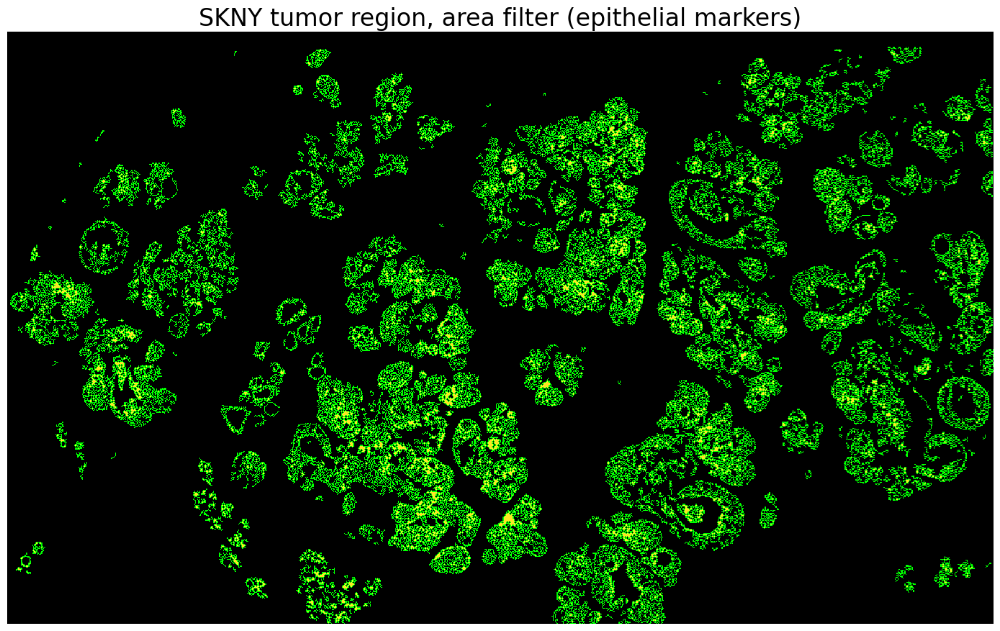

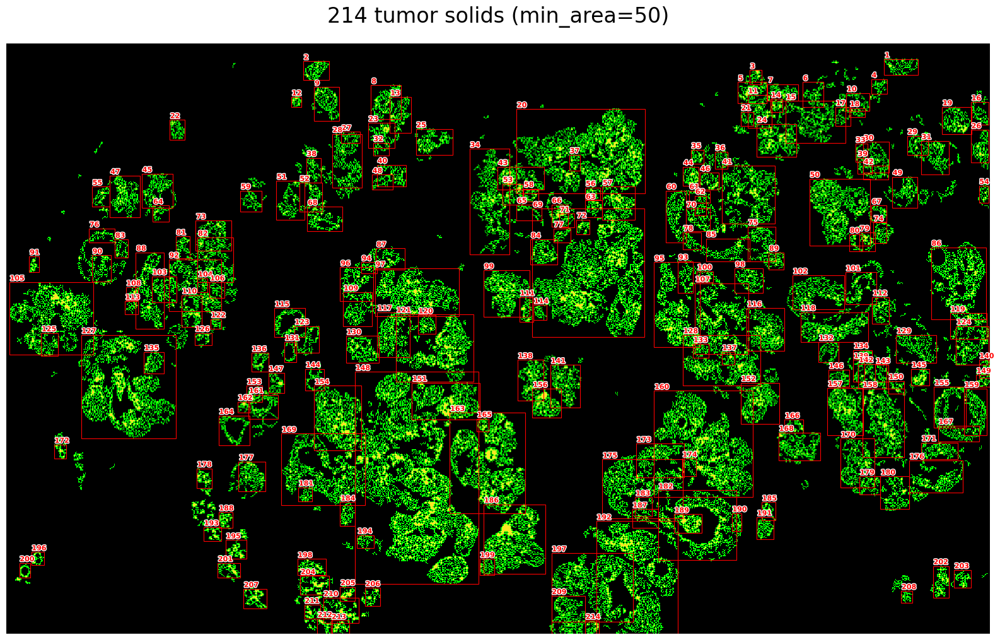

In [6]:
t0 = time.time()
grid = calculate_distance_area_filter(g_new, pos_marker_ls=MARKERS)
assert grid.obs_names.equals(grid0.obs_names)          # rows of G stay aligned with grid.obs
print(f"SKNY (area filter): {time.time()-t0:.1f} s;  speck filter: {grid.uns['speck_filter']}")

MIN_AREA = 50
solid = extract_tumor_solids(grid, section_um=None, min_area=MIN_AREA, verbose=False)
labels_img, stats, centroids = label_solid_regions(grid, min_area=MIN_AREA)
print(f"tumor solids (min_area={MIN_AREA} grid squares = {MIN_AREA*100:,} µm²): {len(solid.obs)}")

fig, ax = plt.subplots(figsize=(14, 9), dpi=100)
ax.imshow(cv2.cvtColor(grid.uns["marker_delineation"], cv2.COLOR_BGR2RGB), interpolation="nearest")
ax.set_title("SKNY tumor region, area filter (epithelial markers)"); ax.axis("off")
plt.tight_layout(); plt.show()

from scomv.tumor_solid import plot_tumor_solids
ax = plot_tumor_solids(solid, figsize=(16, 10.5), dpi=100, id_fontsize=8,
                       title=f"{len(solid.obs)} tumor solids (min_area={MIN_AREA})")
for t in ax.texts:            # 214 ids: keep them small (exempt from the global font bump)
    t._no_font_bump = True
plt.show()

## 3. Cell annotation

The provided cell groups are joined by `cell_id`. Tumor-cell groups (DCIS subtypes, apocrine) are the reference
objects; the 13 non-tumor groups are scored.

In [7]:
ann = pd.read_csv(ANN).set_index("cell_id")
cell_df = (adata.obs[["imagecol", "imagerow"]].join(ann[["group"]]).dropna()
           .rename(columns={"group": "Cluster"}))
print(f"annotated cells: {len(cell_df):,} / {adata.n_obs:,}")
NON_TUMOR_TYPES = [
    "T Lymphocytes", "Macrophages", "Myeloid Cells", "Dendritic Cells", "CXCL14+ Fibroblasts",
    "CAFs, Low Grade DCIS Associated", "CAFs, High Grade DCIS Associated", "Pericytes", "Endothelial Cells",
    "Myoepithelial Cells", "Plasma & Mast Cell Mixture", "Plasma Cells", "Mast Cells",
]
cell_df["Cluster"].value_counts().to_frame("cells")

annotated cells: 170,045 / 170,057


,cells
Cluster,
11q13 High Grade DCIS Cells,64036
"CAFs, Low Grade DCIS Associated",24442
Luminal-like Amorphous DCIS Cells,13028
Basal-like Structured DCIS Cells,8760
Endothelial Cells,8624
Myoepithelial Cells,8438
Pericytes,8087
T Lymphocytes,8018
CXCL14+ Fibroblasts,4936


## 4. Cell-type uniformity around each solid

Same functions and parameters as the tutorial / main text: per-(solid, cell type) polar histograms of the cells'
shortest vectors to the solid boundary, normalised angular entropy in each 10 µm ring from 10 to 100 µm outside the
boundary multiplied by the confidence factor 1 − exp(−n/12), then the distance-weighted mean (weight √(15/d)).

In [8]:
BIN_SIZE, MARGIN_BINS, MIN_CELLS = 10, 15, 5
DIST_BINS = {"10-20µm": 16, "20-30µm": 17, "30-40µm": 18, "40-50µm": 19, "50-60µm": 20,
             "60-70µm": 21, "70-80µm": 22, "80-90µm": 23, "90-100µm": 24}
BIN_WEIGHTS = {"10-20µm": 1.0, **{k: np.sqrt(15 / (15 + 10 * i)) for i, k in enumerate(DIST_BINS) if i > 0}}
RADIUS_BINS, ANGLE_BINS = np.arange(-150, 310, 10), np.arange(-180, 181, 30)

t0 = time.time()
solid_results = compute_per_solid_polar_counts(
    grid, solid, cell_df, NON_TUMOR_TYPES,
    bin_size=BIN_SIZE, margin_bins=MARGIN_BINS, min_cells=MIN_CELLS, cluster_col="Cluster")
uniformity_mats, _ = compute_uniformity(solid_results, NON_TUMOR_TYPES, DIST_BINS, n_ref=12)
feat_all = distance_weighted_mean(uniformity_mats, BIN_WEIGHTS)
print(f"{time.time()-t0:.1f} s;  feature matrix {feat_all.shape} (solids x cell types)")

coverage = pd.Series({ct: len(solid_results[ct]) for ct in NON_TUMOR_TYPES}, name="solids with >=5 cells")
summary = pd.concat([coverage, feat_all.mean().rename("mean uniformity")], axis=1)
summary

15.9 s;  feature matrix (214, 13) (solids x cell types)


,solids with >=5 cells,mean uniformity
T Lymphocytes,204,0.073682
Macrophages,211,0.038925
Myeloid Cells,78,0.006423
Dendritic Cells,191,0.055142
CXCL14+ Fibroblasts,212,0.067897
"CAFs, Low Grade DCIS Associated",208,0.256239
"CAFs, High Grade DCIS Associated",143,0.086981
Pericytes,214,0.104809
Endothelial Cells,214,0.120101
Myoepithelial Cells,202,0.091612


Three cell types (Myeloid cells, Plasma cells, Mast cells) are rare around the solids and have a mean uniformity
< 0.01; after column standardisation inside `ward_cluster` they would contribute mostly noise, so they are excluded
from clustering (criterion: mean uniformity ≥ 0.01 and present in ≥ 50 % of solids).

In [9]:
CELL_TYPES = [ct for ct in NON_TUMOR_TYPES
              if feat_all[ct].mean() >= 0.01 and coverage[ct] >= 0.5 * len(feat_all)]
feat = feat_all[CELL_TYPES]
print("cell types used for clustering:", CELL_TYPES)

cell types used for clustering: ['T Lymphocytes', 'Macrophages', 'Dendritic Cells', 'CXCL14+ Fibroblasts', 'CAFs, Low Grade DCIS Associated', 'CAFs, High Grade DCIS Associated', 'Pericytes', 'Endothelial Cells', 'Myoepithelial Cells', 'Plasma & Mast Cell Mixture']


## 5. Ward clustering of solids

In [10]:
X_std = StandardScaler().fit_transform(feat.values)
_, Z = ward_cluster(feat, n_clusters=2)
sil = {k: silhouette_score(X_std, fcluster(Z, k, criterion="maxclust")) for k in range(2, 11)}
sizes = {k: sorted(np.bincount(fcluster(Z, k, criterion="maxclust"))[1:].tolist(), reverse=True) for k in sil}
display(pd.DataFrame({"silhouette": sil, "cluster sizes": sizes}).round(3))

# k = 4 has the highest silhouette among k >= 3, but leaves one cluster with 135 of 214 solids;
# the next cut of the dendrogram (k = 5) splits exactly that cluster (135 -> 90 + 45), all other clusters unchanged.
K_BEST_SIL = max((k for k in sil if k >= 3), key=sil.get)
N_CLUSTERS = 5
l4, l5 = (fcluster(Z, k, criterion="maxclust") for k in (K_BEST_SIL, N_CLUSTERS))
print(f"highest silhouette among k >= 3: k = {K_BEST_SIL} ({sil[K_BEST_SIL]:.3f});  used: k = {N_CLUSTERS} ({sil[N_CLUSTERS]:.3f})")
display(pd.crosstab(pd.Series(l4, name=f"k={K_BEST_SIL}"), pd.Series(l5, name=f"k={N_CLUSTERS}")))

,silhouette,cluster sizes
2,0.542,"[185, 29]"
3,0.306,"[116, 69, 29]"
4,0.314,"[116, 69, 22, 7]"
5,0.277,"[116, 53, 22, 16, 7]"
6,0.283,"[116, 53, 16, 15, 7, 7]"
7,0.231,"[59, 57, 53, 16, 15, 7, 7]"
8,0.232,"[59, 57, 53, 16, 15, 7, 6, 1]"
9,0.239,"[59, 57, 53, 16, 9, 7, 6, 6, 1]"
10,0.263,"[59, 53, 40, 17, 16, 9, 7, 6, 6, 1]"


highest silhouette among k >= 3: k = 4 (0.314);  used: k = 5 (0.277)


k=5,1,2,3,4,5
k=4,,,,,
1,7,0,0,0,0
2,0,22,0,0,0
3,0,0,116,0,0
4,0,0,0,16,53


Clusters are renumbered by decreasing mean T-lymphocyte uniformity (as in the tutorial). The cluster with the
lowest overall cell-type uniformity is used below as the reference when picking example solids.

{'c1': 7, 'c2': 22, 'c3': 16, 'c4': 116, 'c5': 53}   reference cluster: c4


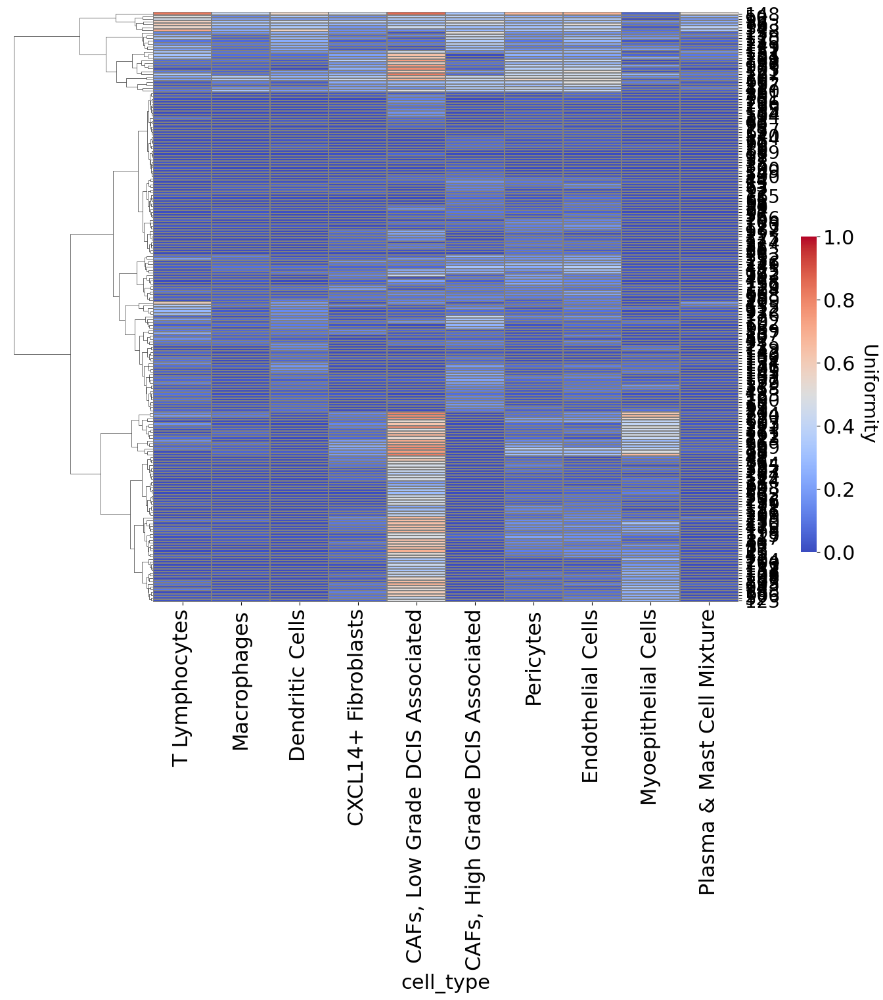

In [11]:
labels, Z = ward_cluster(feat, n_clusters=N_CLUSTERS)
labels, _ = remap_clusters_by_reference(labels, feat, ref_col="T Lymphocytes", ascending=False)
cluster_of_solid = dict(zip(feat.index, labels))
cluster_sizes = pd.Series(labels).value_counts().sort_index()
PALETTE = {0: "#e6194b", 1: "#f58231", 2: "#3cb44b", 3: "#4363d8", 4: "#911eb4", 5: "#42d4f4", 6: "#f032e6"}
TESTABLE = [k for k in range(N_CLUSTERS) if cluster_sizes[k] >= 3]
REF_CLUSTER = min(TESTABLE, key=lambda k: feat[labels == k].values.mean())
print(cluster_sizes.rename(lambda k: f"c{k + 1}").to_dict(), "  reference cluster:", f"c{REF_CLUSTER + 1}")
pd.DataFrame({"solid": feat.index, "cluster": labels + 1}).to_csv(f"{OUT}/solid_clusters.tsv", sep="\t", index=False)

plot_uniformity_heatmap(feat, Z, figsize=(12, 12), xtick_fontsize=11, ytick_fontsize=8)
plt.show()

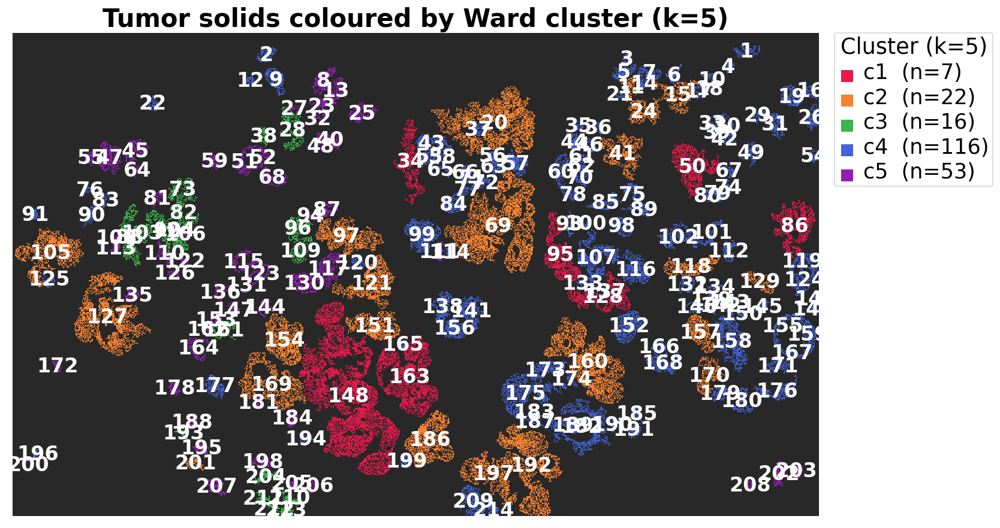

In [12]:
ax, cluster_img = plot_cluster_map(labels_img, solid.obs, cluster_of_solid, n_clusters=N_CLUSTERS,
                                   palette=PALETTE, id_fontsize=8, figsize=(14, 9),
                                   title=f"Tumor solids coloured by Ward cluster (k={N_CLUSTERS})")
fix_cluster_labels(ax.figure)
plt.show()

### 5a. Cell-type composition of the solids in each cluster

Each cell is assigned to the grid square it falls in and, through `solid.shortest["solid"]` (grid squares inside a
solid, distance ≤ 0), to a solid (0 = not inside any solid). For every solid the fraction of each annotated cell
group among its cells is computed, and the fractions are compared across clusters. This is the composition *inside*
the solids, whereas the uniformity clustering describes the cells *around* them.

cells: 170,045 annotated;  inside the 214 clustered solids: 90,914


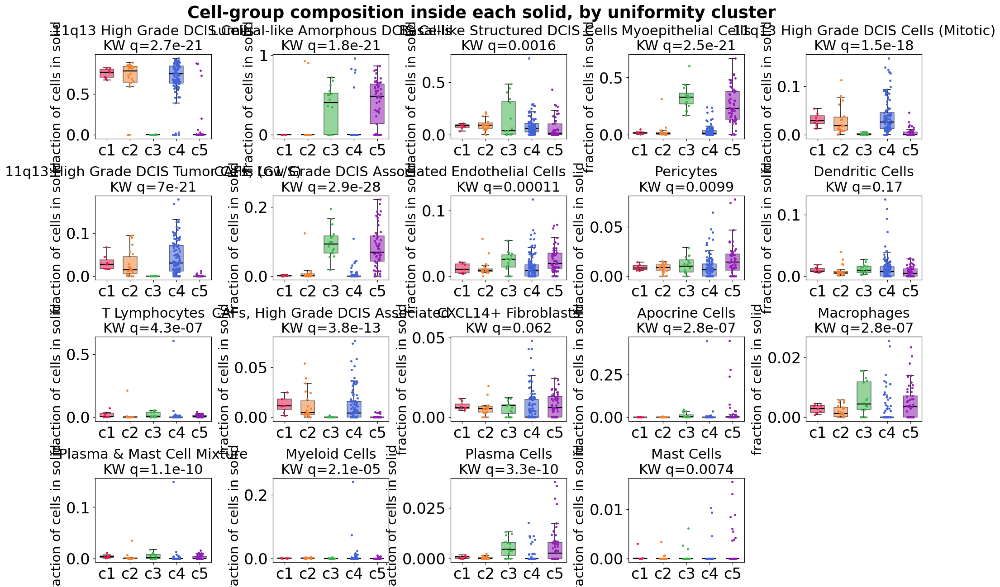

In [13]:
cell_x, cell_y = adata.obs["imagecol"].values, adata.obs["imagerow"].values
xe, ye = grid.uns["grid_xedges"], grid.uns["grid_yedges"]
rng_plot = np.random.default_rng(1)
xy_to_solid = solid.shortest["solid"].to_dict()                 # {(x_bin, y_bin): solid id}
from scomv.preparation.grid_index import points_to_grid_ij   # stlearn's rule (int coordinates, grid edges)
x_bin, y_bin = points_to_grid_ij(cell_x, cell_y, grid)
cell_solid = pd.Series([xy_to_solid.get((int(a), int(b)), 0) for a, b in zip(x_bin, y_bin)],
                       index=adata.obs_names, name="solid_id")
in_solid = cell_df.join(cell_solid)
in_solid = in_solid[in_solid.solid_id.isin(feat.index)]
print(f"cells: {len(cell_df):,} annotated;  inside the {len(feat)} clustered solids: {len(in_solid):,}")

comp = in_solid.groupby(["solid_id", "Cluster"]).size().unstack(fill_value=0)
comp_frac = comp.div(comp.sum(axis=1), axis=0)
comp_frac = comp_frac[comp.sum().sort_values(ascending=False).index]      # most frequent groups first
comp_frac["cluster"] = comp_frac.index.map(cluster_of_solid).astype(int)
comp_frac.assign(cluster=comp_frac.cluster + 1).to_csv(f"{OUT}/solid_celltype_composition.tsv", sep="\t")
cell_groups = [c for c in comp_frac.columns if c != "cluster"]

# Kruskal-Wallis across clusters per cell group (clusters with >= 3 solids), BH over groups
kw = {}
for ct in cell_groups:
    d = [comp_frac.loc[comp_frac.cluster == k, ct].values for k in TESTABLE]
    kw[ct] = kruskal(*d).pvalue if len(d) > 1 else np.nan
kw_q = pd.Series(multipletests(pd.Series(kw).fillna(1), method="fdr_bh")[1], index=cell_groups)

ncols = 5
nrows = int(np.ceil(len(cell_groups) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.6, nrows * 3.0), dpi=110)
axes = axes.ravel()
for ax, ct in zip(axes, cell_groups):
    data = [comp_frac.loc[comp_frac.cluster == k, ct].values for k in range(N_CLUSTERS)]
    bp = ax.boxplot(data, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops=dict(color="black", lw=1.5))
    for patch, k in zip(bp["boxes"], range(N_CLUSTERS)):
        patch.set_facecolor(PALETTE[k]); patch.set_alpha(0.55)
    for k, d in enumerate(data):
        ax.scatter(np.full(len(d), k + 1) + rng_plot.uniform(-0.15, 0.15, len(d)), d, s=5, color=PALETTE[k], zorder=3)
    ax.set_xticks(range(1, N_CLUSTERS + 1), [f"c{k + 1}" for k in range(N_CLUSTERS)])
    ax.set_title(f"{ct}\nKW q={kw_q[ct]:.2g}", fontsize=8)
    ax.set_ylabel("fraction of cells in solid", fontsize=7)
for ax in axes[len(cell_groups):]: ax.axis("off")
fig.suptitle("Cell-group composition inside each solid, by uniformity cluster", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

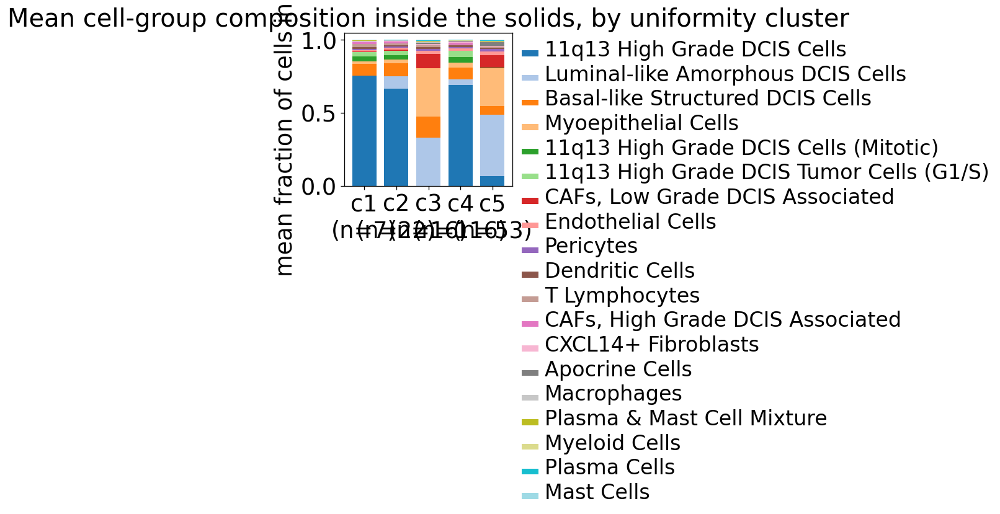

cluster,c1,c2,c3,c4,c5,KW_q
Cluster,,,,,,
11q13 High Grade DCIS Cells,0.755,0.666,0.001,0.694,0.068,0.000
Luminal-like Amorphous DCIS Cells,0.000,0.083,0.329,0.034,0.418,0.000
Basal-like Structured DCIS Cells,0.081,0.089,0.144,0.083,0.063,0.002
Myoepithelial Cells,0.019,0.029,0.331,0.032,0.259,0.000
11q13 High Grade DCIS Cells (Mitotic),0.032,0.030,0.002,0.037,0.004,0.000
11q13 High Grade DCIS Tumor Cells (G1/S),0.032,0.029,0.000,0.042,0.001,0.000
"CAFs, Low Grade DCIS Associated",0.002,0.009,0.098,0.003,0.084,0.000
Endothelial Cells,0.012,0.012,0.023,0.014,0.025,0.000
Pericytes,0.009,0.008,0.011,0.009,0.016,0.010


In [14]:
clust_mean_comp = comp_frac.groupby("cluster")[cell_groups].mean()
fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
clust_mean_comp.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", width=0.75)
ax.set_xticklabels([f"c{k + 1}\n(n={cluster_sizes[k]})" for k in clust_mean_comp.index], rotation=0)
ax.set_xlabel(""); ax.set_ylabel("mean fraction of cells in solid")
ax.set_title("Mean cell-group composition inside the solids, by uniformity cluster")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()
display(clust_mean_comp.T.rename(columns=lambda k: f"c{k + 1}").assign(KW_q=kw_q).round(3))

## 6. Cell types with significantly higher uniformity in each cluster

For every cluster with ≥ 3 solids, each cell type is tested one-vs-rest (cluster *k* vs all other solids,
one-sided Mann–Whitney U, alternative = greater). BH-FDR is applied over all (cluster × cell type) tests. A
single-solid cluster cannot be tested and is only described. AUC = U / (n₁n₂) is the probability that a solid of
cluster *k* scores higher than a solid outside it.

In [15]:
def one_vs_rest(mat, labels, clusters):
    rows = []
    for k in clusters:
        ink = labels == k
        for col in mat.columns:
            x, y = mat.loc[ink, col].values, mat.loc[~ink, col].values
            u, p = mannwhitneyu(x, y, alternative="greater")
            rows.append(dict(cluster=k, feature=col, n_in=int(ink.sum()), mean_in=x.mean(), mean_out=y.mean(),
                             auc=u / (len(x) * len(y)), p=p))
    return pd.DataFrame(rows)

cell_tests = one_vs_rest(feat, labels, TESTABLE)
cell_tests["q"] = multipletests(cell_tests["p"], method="fdr_bh")[1]
cell_tests.assign(cluster=cell_tests.cluster + 1).to_csv(f"{OUT}/celltype_uniformity_one_vs_rest.tsv", sep="\t", index=False)

sig_cells = cell_tests[cell_tests.q < 0.05].sort_values(["cluster", "q"])
sig_cells.assign(cluster=sig_cells.cluster + 1)[["cluster", "feature", "n_in", "mean_in", "mean_out", "auc", "p", "q"]].round(4)

,cluster,feature,n_in,mean_in,mean_out,auc,p,q
6,1,Pericytes,7,0.3490,0.0966,0.9476,0.0000,0.0000
9,1,Plasma & Mast Cell Mixture,7,0.2993,0.0180,0.9993,0.0000,0.0000
0,1,T Lymphocytes,7,0.6050,0.0557,0.9972,0.0000,0.0000
2,1,Dendritic Cells,7,0.3910,0.0438,0.9938,0.0000,0.0000
1,1,Macrophages,7,0.2674,0.0312,0.9876,0.0000,0.0000
5,1,"CAFs, High Grade DCIS Associated",7,0.3624,0.0777,0.9545,0.0000,0.0000
7,1,Endothelial Cells,7,0.4048,0.1105,0.9489,0.0000,0.0001
3,1,CXCL14+ Fibroblasts,7,0.2524,0.0617,0.9441,0.0000,0.0001
17,2,Endothelial Cells,22,0.3298,0.0961,0.9444,0.0000,0.0000
16,2,Pericytes,22,0.2939,0.0831,0.9276,0.0000,0.0000


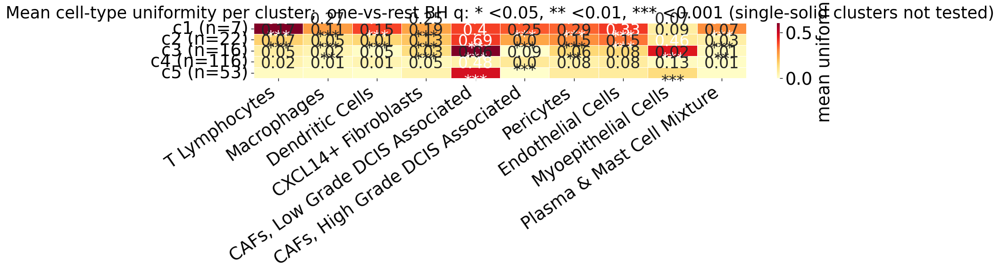

In [16]:
cm = feat.groupby(labels).mean()
star = pd.DataFrame("", index=cm.index, columns=cm.columns)
for _, r in cell_tests.iterrows():
    star.loc[r.cluster, r.feature] = "***" if r.q < 0.001 else "**" if r.q < 0.01 else "*" if r.q < 0.05 else ""
annot = cm.round(2).astype(str) + "\n" + star

fig, ax = plt.subplots(figsize=(13, 0.75 * N_CLUSTERS + 1.2), dpi=120)
sns.heatmap(cm, annot=annot, fmt="", cmap="YlOrRd", vmin=0, vmax=0.6, ax=ax, annot_kws={"size": 8},
            linewidths=0.4, linecolor="white", cbar_kws={"label": "mean uniformity"})
ax.set_yticklabels([f"c{k + 1} (n={cluster_sizes[k]})" for k in cm.index], rotation=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right"); ax.set_xlabel("")
ax.set_title("Mean cell-type uniformity per cluster;  one-vs-rest BH q: * <0.05, ** <0.01, *** <0.001 "
             "(single-solid clusters not tested)", fontsize=9)
plt.tight_layout(); plt.show()

In [17]:
outlier = [int(s) for s in feat.index[labels == 0]] if cluster_sizes[0] == 1 else []
if outlier:
    s0 = outlier[0]
    print(f"c1 is a single solid (solid {s0}, area {stats[s0, cv2.CC_STAT_AREA] * 100 / 1e6:.2f} mm²; "
          f"median solid {np.median(stats[1:, cv2.CC_STAT_AREA]) * 100 / 1e6:.2f} mm²) with high uniformity "
          f"for every cell type:")
    display(feat.loc[s0].round(2).to_frame().T)

### 6a. Actual distributions of the cluster-defining cell types

For each tested cluster, the most significant cell type is shown as

1. the score per cluster (violin + pairwise Mann–Whitney bars, `plot_uniformity_by_cluster`),
2. its cells over the cluster map (`plot_cell_type_over_clusters`),
3. a close-up of a representative solid of the cluster (highest score) and of an area-matched solid of the
   reference cluster: cells of that type in colour, all other cells grey, solid outline in black, dashed line =
   100 µm from the outline,
4. the corresponding polar histograms, shown as the **angular distribution within each 10 µm ring** from 0 to
   150 µm outside the solid (each ring sums to 1; grey = no cells). The uniformity score is the normalised entropy
   of exactly these ring distributions (10–100 µm), so an evenly coloured ring = high uniformity, one bright
   sector = low uniformity.

=== c1: Pericytes   mean U 0.35 vs 0.10   AUC=0.95  q=1.8e-06 ===


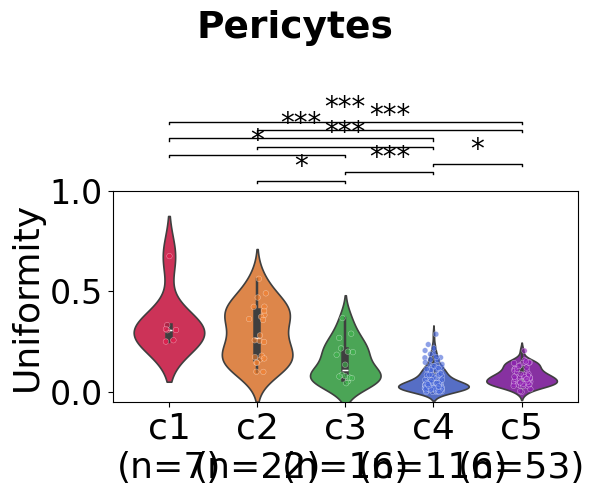

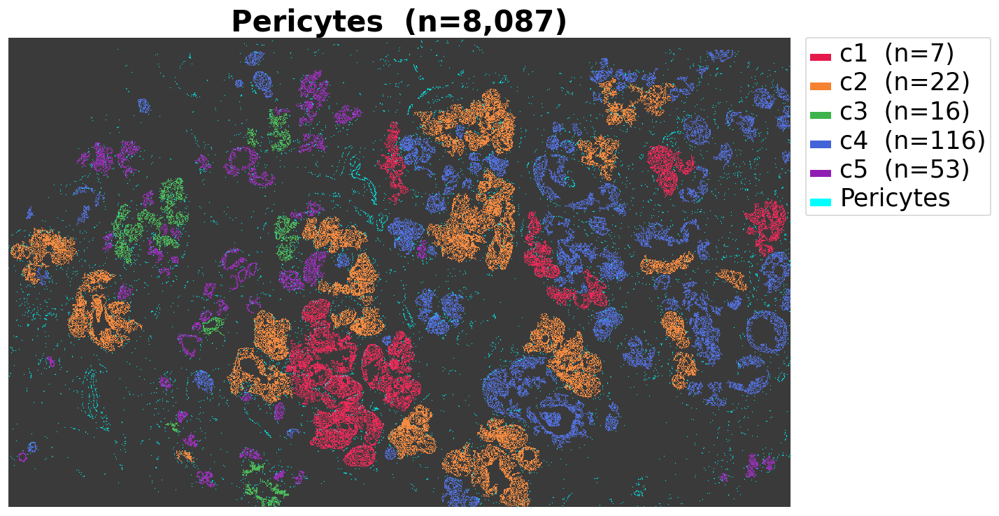

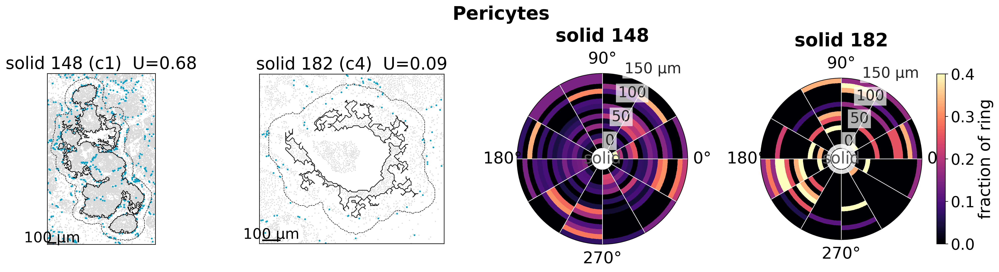

=== c2: Endothelial Cells   mean U 0.33 vs 0.10   AUC=0.94  q=1.1e-10 ===


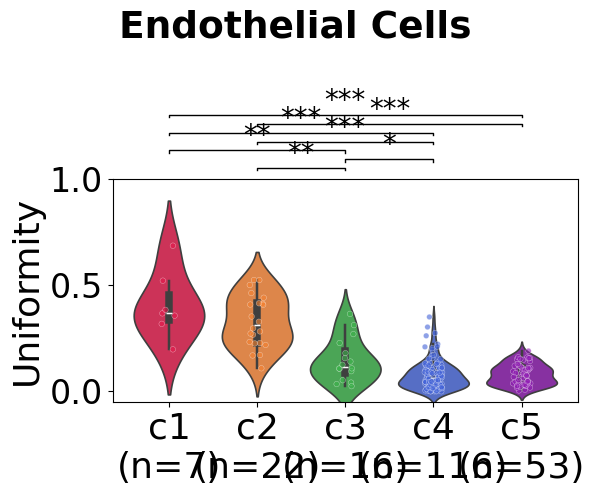

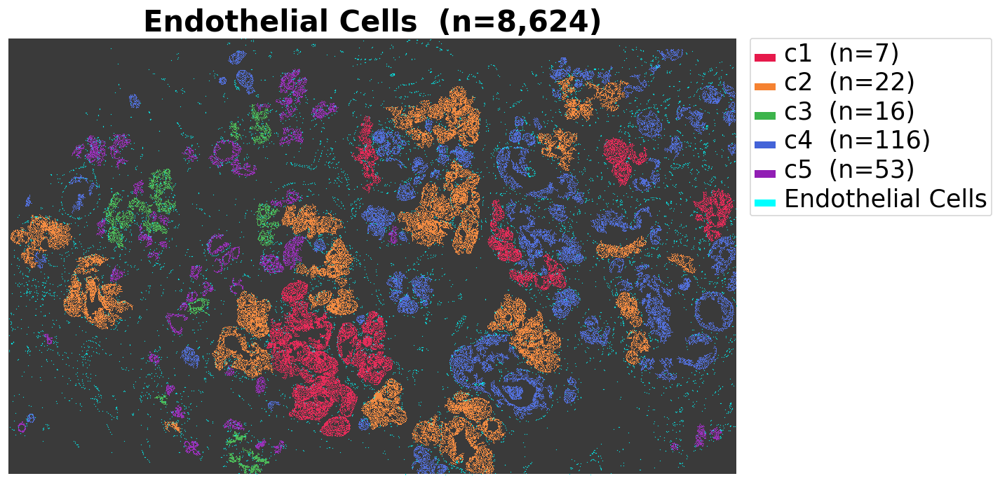

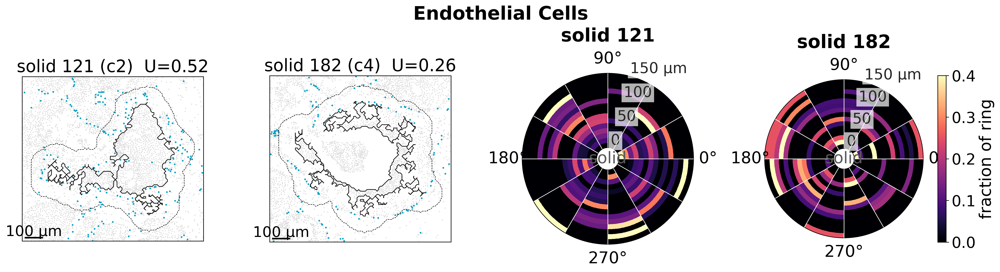

=== c3: Myoepithelial Cells   mean U 0.46 vs 0.06   AUC=1.00  q=2.8e-10 ===


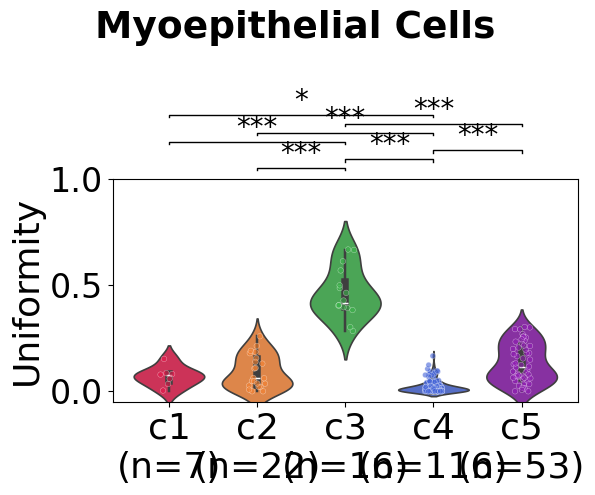

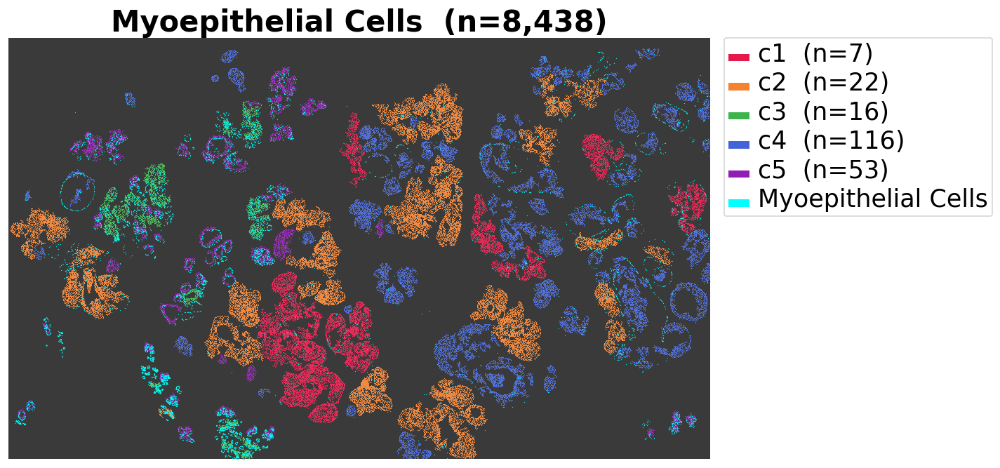

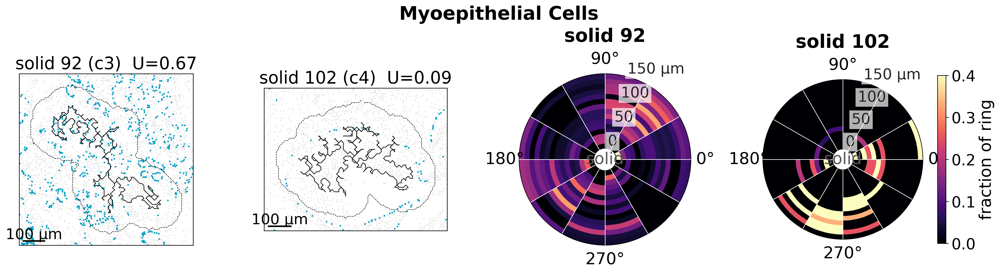

=== c4: CAFs, High Grade DCIS Associated   mean U 0.09 vs 0.08   AUC=0.71  q=8.4e-08 ===


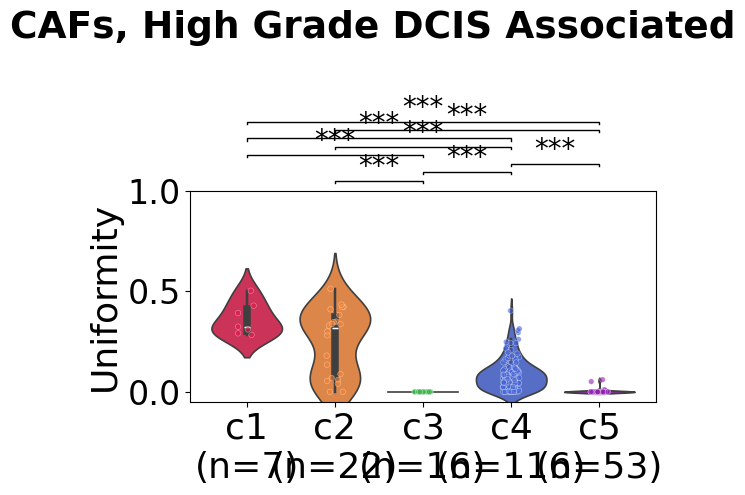

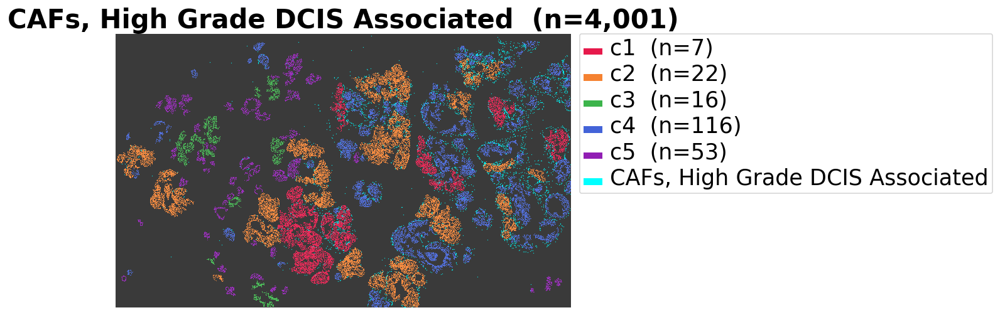

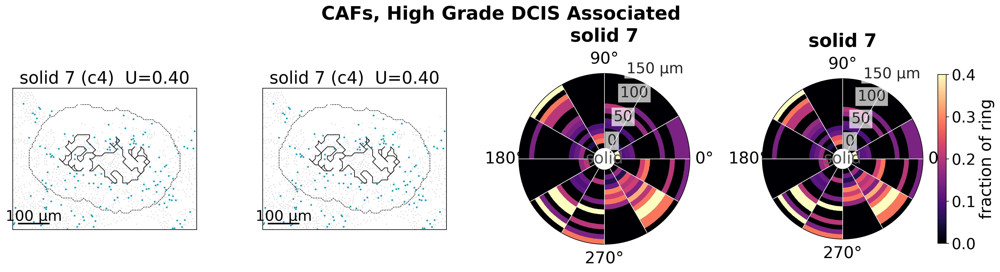

=== c5: CAFs, Low Grade DCIS Associated   mean U 0.48 vs 0.18   AUC=0.83  q=8.1e-12 ===


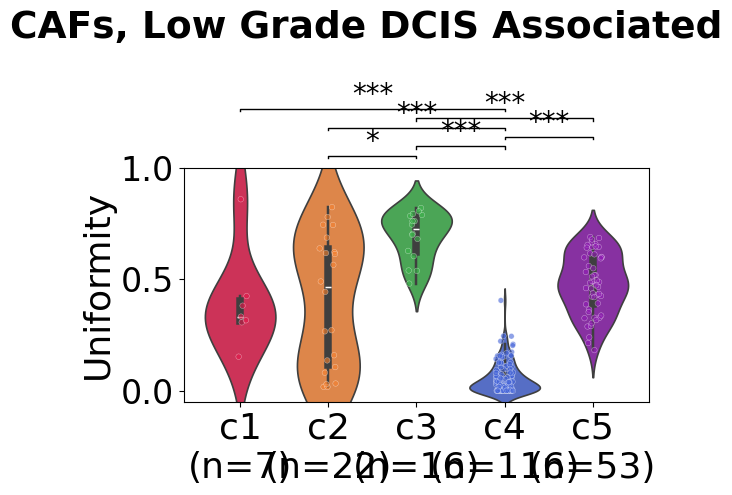

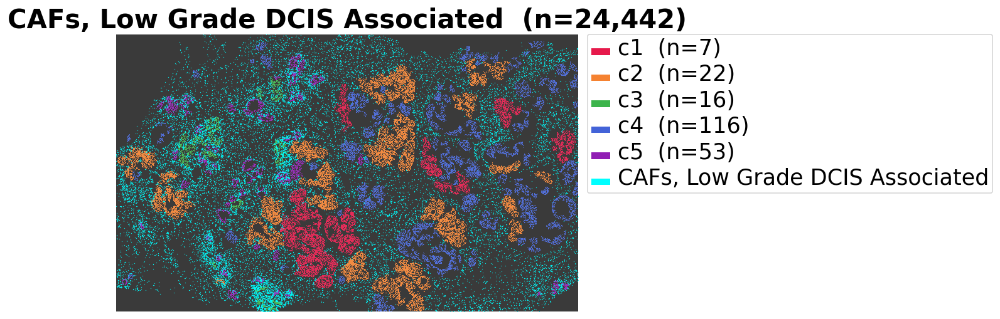

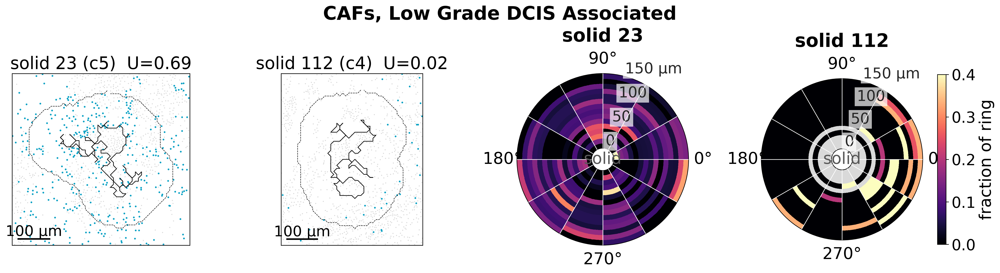

In [18]:
solid_area = pd.Series({int(s): stats[int(s), cv2.CC_STAT_AREA] for s in feat.index})
OUT_ROWS = np.arange(15, 30)          # radius bins 0-10, ..., 140-150 µm (outside the solid)
cell_x, cell_y = adata.obs["imagecol"].values, adata.obs["imagerow"].values
xe, ye = grid.uns["grid_xedges"], grid.uns["grid_yedges"]
dx, dy = np.diff(xe).mean(), np.diff(ye).mean()

def representative_pair(score, k):
    sk = score[labels == k].idxmax()
    ref = feat.index[labels == REF_CLUSTER]
    sr = (np.log(solid_area[ref]) - np.log(solid_area[sk])).abs().idxmin()
    return int(sk), int(sr)

def ring_distribution(h):
    h = np.asarray(h, float)[OUT_ROWS]
    tot = h.sum(axis=1, keepdims=True)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(tot > 0, h / tot, np.nan)

def draw_ring_polar(ax, h, title, colorbar):
    plot_polar_heatmap(ring_distribution(h), RADIUS_BINS[OUT_ROWS[0]:OUT_ROWS[-1] + 2], ANGLE_BINS, ax=ax,
                       cmap="magma", vmin=0, vmax=0.4, boundary_radius=None, center_label="solid",
                       radius_ticks=[0, 50, 100, 150], colorbar=colorbar, cbar_label="fraction of ring",
                       title=title, fontsize=9)

def solid_outline(sid):
    m = (labels_img == sid).astype(np.uint8)
    cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    return [np.c_[xe[0] + (c[:, 0, 0] + 0.5) * dx, ye[0] + (c[:, 0, 1] + 0.5) * dy] for c in cs]

def solid_zoom(ax, sid, values=None, highlight=None, vmax=None, label=""):
    # close-up of one solid: grey cells, coloured cells (expression or a cell-type mask), outline + 100 µm line
    m = (labels_img == sid).astype(np.uint8)
    ys, xs = np.nonzero(m)
    x0, x1 = xe[0] + xs.min() * dx - 150, xe[0] + (xs.max() + 1) * dx + 150
    y0, y1 = ye[0] + ys.min() * dy - 150, ye[0] + (ys.max() + 1) * dy + 150
    sel = (cell_x > x0) & (cell_x < x1) & (cell_y > y0) & (cell_y < y1)
    ax.scatter(cell_x[sel], cell_y[sel], s=2, c="0.85", lw=0)
    if values is not None:
        e = values[sel]; on = e > 0; o = np.argsort(e[on])
        sc_ = ax.scatter(cell_x[sel][on][o], cell_y[sel][on][o], c=e[on][o], s=5, cmap="viridis",
                         vmin=0, vmax=vmax, lw=0)
        plt.colorbar(sc_, ax=ax, fraction=0.04, pad=0.01, label=label)
    if highlight is not None:
        hsel = highlight[sel]
        ax.scatter(cell_x[sel][hsel], cell_y[sel][hsel], s=5, c="#0aa1c4", lw=0, label=label)
    for c in solid_outline(sid):
        ax.plot(np.r_[c[:, 0], c[0, 0]], np.r_[c[:, 1], c[0, 1]], c="k", lw=0.8)
    dil = cv2.dilate(m, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21)))
    for c in cv2.findContours(dil, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]:
        ax.plot(xe[0] + (c[:, 0, 0] + 0.5) * dx, ye[0] + (c[:, 0, 1] + 0.5) * dy, c="k", lw=0.6, ls="--")
    ax.set_xlim(x0, x1); ax.set_ylim(y1, y0); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.plot([x0 + 20, x0 + 120], [y1 - 20, y1 - 20], c="k", lw=2)
    ax.text(x0 + 70, y1 - 30, "100 µm", ha="center", fontsize=7)

top_cell = sig_cells.groupby("cluster").head(1)
for _, r in top_cell.iterrows():
    k, ct = int(r.cluster), r.feature
    print(f"=== c{k + 1}: {ct}   mean U {r.mean_in:.2f} vs {r.mean_out:.2f}   AUC={r.auc:.2f}  q={r.q:.2g} ===")
    plot_uniformity_by_cluster(ct, feat, labels, n_clusters=N_CLUSTERS, palette=PALETTE, singleton_size=80)
    fix_cluster_labels()
    plt.show()
    plot_cell_type_over_clusters(ct, cell_df=cell_df, cluster_img=cluster_img,
                                 origin=(adata.obs.imagecol.min(), adata.obs.imagerow.min()),
                                 cluster_sizes=cluster_sizes.to_dict(), palette=PALETTE,
                                 dot_size=0.6, figsize=(12, 7.5))
    fix_cluster_labels()
    plt.show()
    sk, sr = representative_pair(feat[ct], k)
    is_ct = (adata.obs_names.isin(cell_df.index[cell_df.Cluster == ct]))
    fig = plt.figure(figsize=(18, 4.8), dpi=80)
    for j, sid in enumerate([sk, sr]):
        ax = fig.add_subplot(1, 4, 1 + j)
        solid_zoom(ax, sid, highlight=is_ct, label=ct)
        ax.set_title(f"solid {sid} (c{cluster_of_solid[sid] + 1})  U={feat.loc[sid, ct]:.2f}", fontsize=10)
    for j, sid in enumerate([sk, sr]):
        ax = fig.add_subplot(1, 4, 3 + j, projection="polar")
        draw_ring_polar(ax, solid_results[ct].get(sid, (np.zeros((len(RADIUS_BINS) - 1, len(ANGLE_BINS) - 1)), 0))[0], f"solid {sid}", colorbar=(j == 1))
    fig.suptitle(ct, fontweight="bold"); plt.tight_layout(); plt.show()

## 7. Gene-level uniformity for all 17,878 genes

For every solid and every gene, the expression-weighted polar histogram and the uniformity score are computed
exactly as `compute_gene_uniformity` does (expression-weighted shortest vectors, ties split 1/n, `n_ref=24`), then
collapsed with the same distance weights. `gene_polar_counts` does this for all genes of one solid at once with two
sparse matrix products. The check below compares it with the package function on 200 random genes in 5 solids,
with and without an expression scale factor (`n_scale`).

In [19]:
rng = np.random.default_rng(0)
check_genes = sorted(rng.choice(var_names, 200, replace=False).tolist())
g_chk = with_genes(grid0, G, var_names, check_genes); setattr(g_chk, "shortest", grid.shortest)
max_diff = 0.0
for sid, n_scale in zip(rng.choice(feat.index, 5, replace=False), [1.0, 1.0, 0.5, 2.0, 0.8]):
    sid = int(sid)
    ref = compute_gene_uniformity(g_chk, solid, sid, DIST_BINS, genes=check_genes, n_ref=24, n_scale=n_scale)
    mask, mv, _ = solid_min_vectors(grid, solid, sid)
    sg, mv_pkg, _ = compute_solid_min_vectors(grid, solid, sid)
    assert sg.obs_names.equals(grid.obs_names[mask]) and mv_pkg.equals(mv)
    A, n_expr, _ = gene_polar_counts(G[mask], mv)
    new = uniformity_from_counts(A, n_expr * n_scale, DIST_BINS, n_ref=24).set_axis(var_names).loc[ref.index]
    max_diff = max(max_diff, np.abs(new.values - ref.values).max())
print(f"max |fast - compute_gene_uniformity| over 5 solids x 200 genes x 9 bins: {max_diff:.1e}")
del g_chk

max |fast - compute_gene_uniformity| over 5 solids x 200 genes x 9 bins: 3.3e-16


**Expression-scale correction.** Gene-level uniformity contains the confidence factor 1 − exp(−n/24), which rises
with the amount of expression around a solid. Solids embedded in dense stroma therefore get higher scores for
*all* genes. The main text corrects this for two-group comparisons with the total-expression fold factor
(`compute_expression_fold_factor` / `compute_gene_uniformity_pair`: the expressing-cell count of one group is
scaled by the median per-gene expression ratio). With 67 solids the same idea is applied with a median-of-ratios
size factor per solid, *s* = median over genes of (ROI expression / geometric mean across solids), and the
expressing-cell count is scaled by 1/*s* (`n_scale = 1/s`). Both the corrected and the uncorrected scores are kept.

In [20]:
t0 = time.time()
w = np.array(list(BIN_WEIGHTS.values()))
ring_hists, n_expr_all, totals = {}, {}, {}
for sid in feat.index:
    sid = int(sid)
    mask, mv, _ = solid_min_vectors(grid, solid, sid)
    A, n_expr, tot = gene_polar_counts(G[mask], mv)
    ring_hists[sid], n_expr_all[sid], totals[sid] = A[:, :31, :].astype(np.float32), n_expr, tot
totals = pd.DataFrame(totals, index=var_names).T
expressed_all = (totals > 0).all()
logt = np.log(totals.loc[:, expressed_all])
size_factor = np.exp((logt - logt.mean()).median(axis=1))

def weighted_gene_uniformity(scale):
    out = {}
    for sid in feat.index:
        U = uniformity_from_counts(ring_hists[sid], n_expr_all[sid] * scale[sid], DIST_BINS, n_ref=24).values
        out[sid] = (U * w).sum(axis=1) / w.sum()
    return pd.DataFrame(out, index=var_names).T            # solids x genes

gene_wu_raw = weighted_gene_uniformity(pd.Series(1.0, index=feat.index))
gene_wu = weighted_gene_uniformity(1.0 / size_factor)
print(f"gene uniformity for {gene_wu.shape[0]} solids x {gene_wu.shape[1]:,} genes in {time.time()-t0:.1f} s")
gene_wu.to_csv(f"{OUT}/gene_uniformity_weighted_sizefactor_solid_x_gene.csv.gz")
gene_wu_raw.to_csv(f"{OUT}/gene_uniformity_weighted_raw_solid_x_gene.csv.gz")

display(pd.DataFrame({
    "size factor (median)": size_factor.groupby(labels).median(),
    "mean gene U, uncorrected": gene_wu_raw.mean(axis=1).groupby(labels).mean(),
    "mean gene U, size-factor corrected": gene_wu.mean(axis=1).groupby(labels).mean(),
}).rename(lambda k: f"c{k + 1}").round(3))

GENE_MIN_MEAN = 0.05
genes_tested = gene_wu.columns[gene_wu.mean() >= GENE_MIN_MEAN]
print(f"genes with mean corrected uniformity >= {GENE_MIN_MEAN}: {len(genes_tested):,} (tested)")

gene uniformity for 214 solids x 17,878 genes in 20.4 s


,size factor (median),"mean gene U, uncorrected","mean gene U, size-factor corrected"
c1,3.319,0.204,0.061
c2,3.194,0.149,0.061
c3,1.216,0.103,0.085
c4,0.880,0.059,0.057
c5,0.693,0.042,0.054


genes with mean corrected uniformity >= 0.05: 7,177 (tested)


## 8. Genes with significantly higher uniformity in each cluster

Same one-vs-rest test as for cell types (one-sided Mann–Whitney U), BH-FDR within each cluster over the tested
genes, on the size-factor-corrected scores. For comparison, the number of significant genes without the
correction is also given: without it, the stroma-rich cluster shows a uniform increase over almost all genes, which
is a cellularity effect rather than a gene-specific one.

In [21]:
gene_tests = one_vs_rest(gene_wu[genes_tested], labels, TESTABLE).rename(columns={"feature": "gene"})
gene_tests["q"] = gene_tests.groupby("cluster")["p"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
raw_tests = one_vs_rest(gene_wu_raw[genes_tested], labels, TESTABLE)
raw_tests["q"] = raw_tests.groupby("cluster")["p"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
n_sig = gene_tests[gene_tests.q < 0.05].groupby("gene").size()
gene_tests["n_clusters_sig"] = gene_tests.gene.map(n_sig).fillna(0).astype(int)
gene_tests.assign(cluster=gene_tests.cluster + 1).to_csv(f"{OUT}/gene_uniformity_one_vs_rest.tsv.gz", sep="\t", index=False)

cnt = lambda t, extra=True: t[(t.q < 0.05) & extra].groupby("cluster").size().reindex(TESTABLE, fill_value=0).values
pd.DataFrame({
    "solids": cluster_sizes[TESTABLE].values,
    "q<0.05 (uncorrected)": cnt(raw_tests),
    "q<0.05 (size-factor corrected)": cnt(gene_tests),
    "  of which AUC>=0.9": cnt(gene_tests, gene_tests.auc >= 0.9),
    "  of which only in this cluster": cnt(gene_tests, gene_tests.n_clusters_sig == 1),
}, index=[f"c{k + 1}" for k in TESTABLE])

,solids,q<0.05 (uncorrected),q<0.05 (size-factor corrected),of which AUC>=0.9,of which only in this cluster
c1,7,7177,112,44,9
c2,22,7177,44,0,11
c3,16,5730,5592,1616,3871
c4,116,27,2246,0,1477
c5,53,77,867,14,1


In [22]:
TOP_N = 20
top_genes = {}
for k in TESTABLE:
    s = gene_tests[(gene_tests.cluster == k) & (gene_tests.q < 0.05)].sort_values(["auc", "p"], ascending=[False, True])
    top_genes[k] = s.gene.head(TOP_N).tolist()
    if len(s):
        print(f"c{k + 1} ({cluster_sizes[k]} solids): {len(s)} genes with q<0.05 — top {min(TOP_N, len(s))} by AUC")
        display(s.head(TOP_N)[["gene", "mean_in", "mean_out", "auc", "q", "n_clusters_sig"]].round(4).reset_index(drop=True))
    else:
        print(f"c{k + 1} ({cluster_sizes[k]} solids): no gene with q<0.05")

c1 (7 solids): 112 genes with q<0.05 — top 20 by AUC


,gene,mean_in,mean_out,auc,q,n_clusters_sig
0,GIMAP7,0.1657,0.0681,0.9738,0.0000,3
1,TRAC,0.1819,0.0481,0.9731,0.0000,2
2,CYBB,0.1363,0.0491,0.9627,0.0002,2
3,CD74,0.1690,0.0603,0.9572,0.0002,2
4,LAPTM5,0.2660,0.1060,0.9572,0.0002,2
5,ARHGAP4,0.1508,0.0612,0.9565,0.0002,2
6,GIMAP4,0.1699,0.0710,0.9565,0.0002,3
7,CTSS,0.1950,0.0776,0.9551,0.0002,2
8,EVI2B,0.1522,0.0566,0.9517,0.0002,2
9,HCLS1,0.1439,0.0491,0.9517,0.0002,1


c2 (22 solids): 44 genes with q<0.05 — top 20 by AUC


,gene,mean_in,mean_out,auc,q,n_clusters_sig
0,PLVAP,0.0833,0.0482,0.8267,0.0019,1
1,SHANK3,0.1087,0.0688,0.8059,0.0035,2
2,PECAM1,0.1880,0.1282,0.8030,0.0035,2
3,LRRC32,0.1029,0.0588,0.8009,0.0035,2
4,APOLD1,0.1374,0.0941,0.7940,0.0040,1
5,GIMAP7,0.1086,0.0670,0.7914,0.0040,3
6,RAMP2,0.1180,0.0759,0.7912,0.0040,3
7,SYNPO,0.1123,0.0733,0.7857,0.0052,1
8,AQP1,0.0908,0.0556,0.7798,0.0070,2
9,ASPN,0.1108,0.0713,0.7768,0.0072,1


c3 (16 solids): 5592 genes with q<0.05 — top 20 by AUC


,gene,mean_in,mean_out,auc,q,n_clusters_sig
0,HYCC1,0.1856,0.0497,0.9953,0.0,2
1,NFIB,0.3916,0.1583,0.9946,0.0,2
2,COL17A1,0.2052,0.0563,0.9902,0.0,2
3,TP63,0.2103,0.0631,0.9896,0.0,2
4,CROT,0.1605,0.0753,0.9893,0.0,1
5,CSAD,0.1965,0.0891,0.9890,0.0,2
6,CRYAB,0.1545,0.0429,0.9886,0.0,2
7,IP6K2,0.3103,0.1594,0.9883,0.0,2
8,NAB2,0.1622,0.0657,0.9877,0.0,2
9,FRMD6,0.3009,0.1236,0.9858,0.0,2


c4 (116 solids): 2246 genes with q<0.05 — top 20 by AUC


,gene,mean_in,mean_out,auc,q,n_clusters_sig
0,KCNJ3,0.0939,0.0243,0.8468,0.0,1
1,ELOVL2,0.1913,0.0656,0.8414,0.0,1
2,TMEM132A,0.1898,0.0721,0.8404,0.0,1
3,ALDH4A1,0.0720,0.0242,0.8326,0.0,1
4,C15orf48,0.1257,0.0399,0.8311,0.0,1
5,CCDC86,0.1600,0.0752,0.8307,0.0,1
6,SNX10,0.1846,0.0918,0.8297,0.0,1
7,SLC29A2,0.1942,0.0831,0.8289,0.0,1
8,MAPK8IP2,0.1125,0.0432,0.8256,0.0,1
9,LTO1,0.2204,0.1121,0.8233,0.0,1


c5 (53 solids): 867 genes with q<0.05 — top 20 by AUC


,gene,mean_in,mean_out,auc,q,n_clusters_sig
0,ABCA10,0.2094,0.0641,0.9205,0.0,2
1,NR2F1,0.2758,0.1044,0.9180,0.0,2
2,FBLN5,0.2282,0.0769,0.9135,0.0,2
3,MEIS1,0.1167,0.0412,0.9130,0.0,2
4,ABCA6,0.3334,0.1267,0.9100,0.0,2
5,ADAM33,0.1941,0.0590,0.9080,0.0,2
6,PDGFRA,0.3435,0.1433,0.9079,0.0,2
7,RGMA,0.2083,0.0665,0.9044,0.0,2
8,PLEKHH2,0.2786,0.1176,0.9040,0.0,2
9,ABCA9,0.2323,0.0845,0.9034,0.0,2


In [23]:
# known lineage markers: which cluster(s) show a significant increase (q) — for orientation only
MARKER_GENES = {"immune": ["PTPRC", "CD3E", "CD8A", "CD74", "CXCL9", "LCP2"],
                "vascular": ["PECAM1", "VWF", "CDH5", "RGS5", "PDGFRB"],
                "fibroblast / myoepithelial": ["COL1A1", "PDGFRA", "SFRP1", "ACTA2", "MYH11", "KRT5", "KRT14"]}
rows = []
for grp, gs in MARKER_GENES.items():
    for g in gs:
        if g in set(genes_tested):
            r = gene_tests[gene_tests.gene == g].set_index("cluster")
            rows.append({"group": grp, "gene": g, **{f"c{k + 1} q": r.loc[k, "q"] for k in TESTABLE}})
pd.DataFrame(rows).set_index(["group", "gene"]).style.format("{:.3g}").background_gradient(cmap="Reds_r", vmin=0, vmax=0.1)

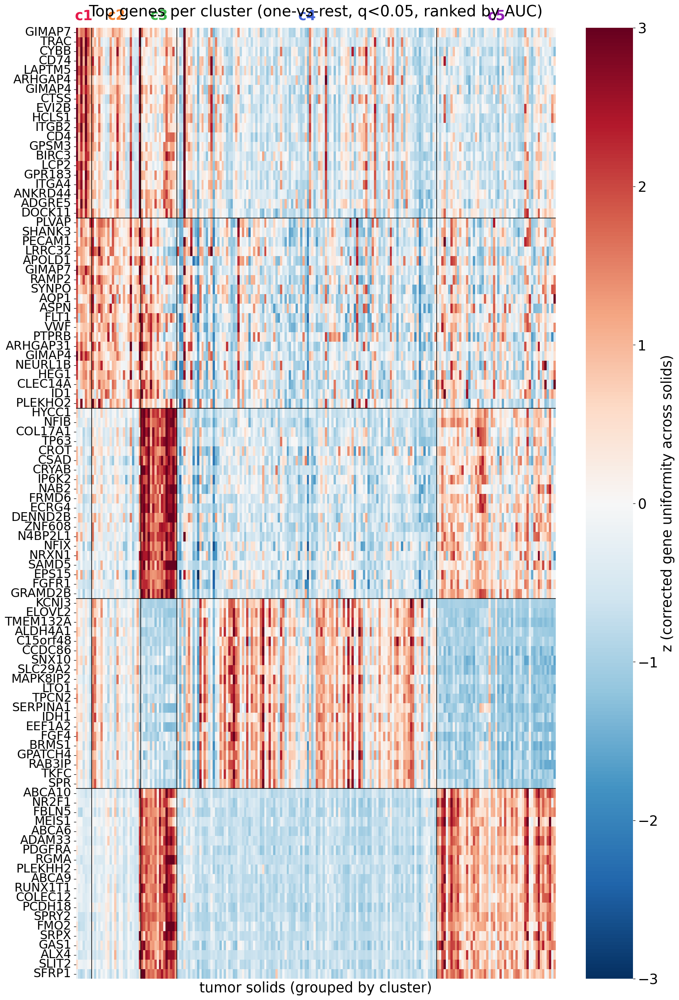

In [24]:
rows_ = [g for k in TESTABLE for g in top_genes[k]]
if rows_:
    order = np.argsort(labels, kind="stable")
    M = gene_wu[rows_].iloc[order]
    Mz = ((M - M.mean()) / M.std(ddof=0)).T
    fig, ax = plt.subplots(figsize=(15, 0.2 * len(rows_) + 2), dpi=120)
    sns.heatmap(Mz, cmap="RdBu_r", center=0, vmin=-3, vmax=3, ax=ax, xticklabels=False,
                cbar_kws={"label": "z (corrected gene uniformity across solids)"})
    bounds = np.cumsum(cluster_sizes.values)
    for b in bounds[:-1]: ax.axvline(b, color="k", lw=1)
    for k, (lo, hi) in enumerate(zip(np.r_[0, bounds[:-1]], bounds)):
        ax.text((lo + hi) / 2, -0.5, f"c{k + 1}", ha="center", va="bottom", color=PALETTE[k], fontweight="bold")
    yb = np.cumsum([len(top_genes[k]) for k in TESTABLE if top_genes[k]])
    for b in yb[:-1]: ax.axhline(b, color="k", lw=1)
    ax.set_xlabel("tumor solids (grouped by cluster)"); ax.set_ylabel(""); ax.tick_params(axis="y", labelsize=7)
    ax.set_title("Top genes per cluster (one-vs-rest, q<0.05, ranked by AUC)", pad=18)
    plt.tight_layout(); plt.show()

### 8a. Actual distributions of the top genes

For the top gene of every cluster with significant genes: the corrected score per cluster, the transcript
counts of the gene per cell around a representative solid of the cluster and around an area-matched solid of the
reference cluster (grey = 0 counts; black = solid outline; dashed = 100 µm), and the per-ring angular
distributions of the gene-weighted shortest vectors (same display as §6a).

=== c1: GIMAP7   mean U 0.17 vs 0.07   AUC=0.97  q=4.4e-05 ===


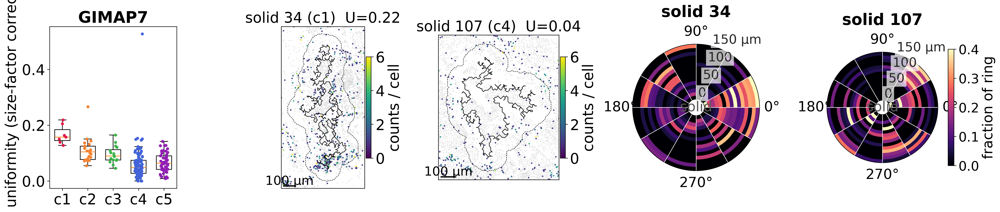

=== c2: PLVAP   mean U 0.08 vs 0.05   AUC=0.83  q=0.0019 ===


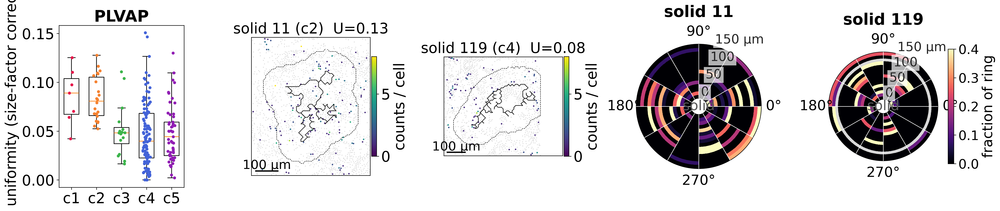

=== c3: HYCC1   mean U 0.19 vs 0.05   AUC=1.00  q=9.9e-09 ===


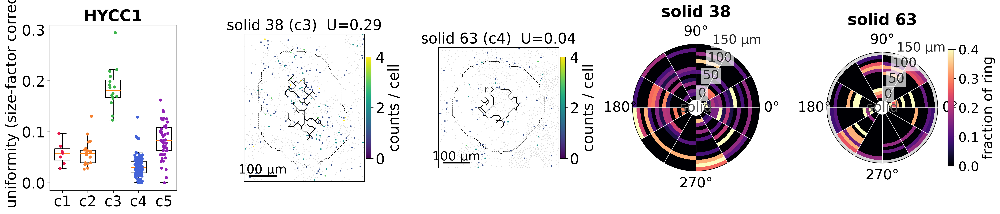

=== c4: KCNJ3   mean U 0.09 vs 0.02   AUC=0.85  q=8.9e-15 ===


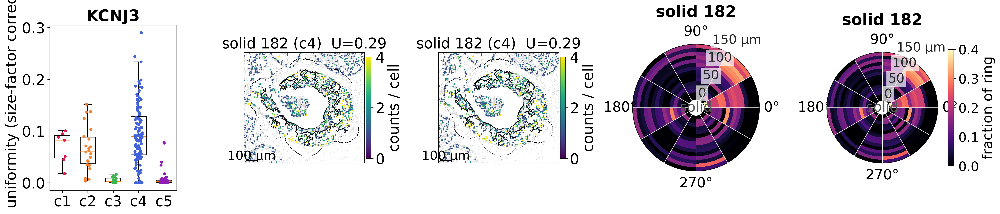

=== c5: ABCA10   mean U 0.21 vs 0.06   AUC=0.92  q=1.3e-16 ===


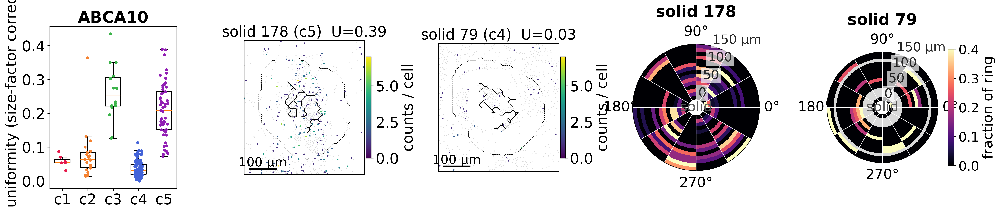

In [25]:
gidx = {g: i for i, g in enumerate(adata.var_names)}
Xc = adata.X.tocsc()
vidx = {g: i for i, g in enumerate(var_names)}
for k in TESTABLE:
    for gene in top_genes[k][:1]:   # top gene of each cluster
        r = gene_tests[(gene_tests.cluster == k) & (gene_tests.gene == gene)].iloc[0]
        print(f"=== c{k + 1}: {gene}   mean U {r.mean_in:.2f} vs {r.mean_out:.2f}   AUC={r.auc:.2f}  q={r.q:.2g} ===")
        sk, sr = representative_pair(gene_wu[gene], k)
        e_all = np.asarray(Xc[:, gidx[gene]].todense()).ravel()
        vmax = max(1.0, np.percentile(e_all[e_all > 0], 99))
        fig = plt.figure(figsize=(21, 4.6), dpi=80)
        ax0 = fig.add_subplot(1, 5, 1)
        data = [gene_wu.loc[labels == c, gene].values for c in range(N_CLUSTERS)]
        ax0.boxplot(data, widths=0.6, showfliers=False)
        for c, dd in enumerate(data):
            ax0.scatter(np.full(len(dd), c + 1) + rng.uniform(-0.15, 0.15, len(dd)), dd, s=12, color=PALETTE[c], zorder=3)
        ax0.set_xticks(range(1, N_CLUSTERS + 1), [f"c{c + 1}" for c in range(N_CLUSTERS)])
        ax0.set_ylabel("gene uniformity (size-factor corrected)"); ax0.set_title(gene, fontweight="bold")
        for j, sid in enumerate([sk, sr]):
            ax = fig.add_subplot(1, 5, 2 + j)
            solid_zoom(ax, sid, values=e_all, vmax=vmax, label="counts / cell")
            ax.set_title(f"solid {sid} (c{cluster_of_solid[sid] + 1})  U={gene_wu.loc[sid, gene]:.2f}", fontsize=10)
        for j, sid in enumerate([sk, sr]):
            ax = fig.add_subplot(1, 5, 4 + j, projection="polar")
            draw_ring_polar(ax, ring_hists[sid][vidx[gene]], f"solid {sid}", colorbar=(j == 1))
        plt.tight_layout(); plt.show()

## 9. One tumor solid in detail: gene distribution clustering

The solid analysed here was chosen as the most typical solid of the immune-rich cluster (closest to the cluster
centroid in the standardised cell-type uniformity space, large ROI of ~7,000 cells); it was solid no. 163 when the
solids were first defined. Solid ids depend on the mask, so it is located here by position (grid x 445–520,
y 370–470, i.e. x ≈ 4,450–5,200 µm, y ≈ 3,700–4,700 µm) and its current id is printed.

Steps (as in the *Gene Distribution Clustering* tutorial):

1. candidate genes: ROI total transcripts > 1 % of the number of ROI cells,
2. **spatially variable genes**: Moran's I on the ROI cells (squidpy), FDR < 0.05, top 3,000 by I. With ~16,000
   candidates the PCoA is otherwise dominated by barely-expressed genes,
3. expression-weighted polar histograms → MINAS similarity → PCoA,
4. two-stage HDBSCAN (stage 1: PCoA + inside/outside density ratio A, clusters with mean A ≥ 1.2 are "internal";
   stage 2: the remaining genes by PCoA + uniformity), settings chosen by DBCV among those giving 5–20 clusters,
5. mean polar distribution, presence-fraction map and GO enrichment per gene cluster.

solid 163 (cluster c1): ROI 5,817 grid squares (30 inside), 7,313 cells
candidate genes (ROI total > 1% of ROI cells (> 73.1 transcripts): 16,124 / 17,878


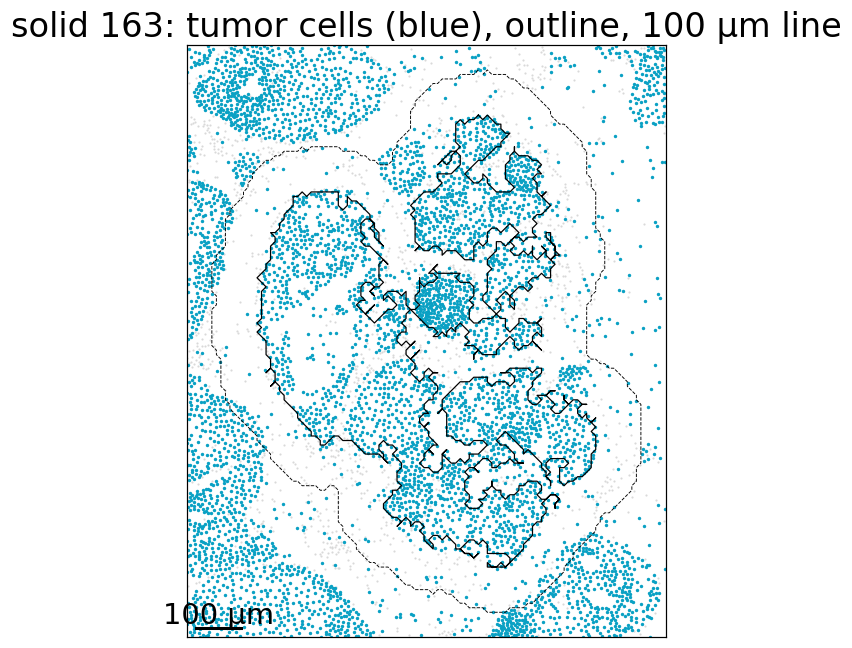

In [26]:
from atera_utils import minas_distance, pcoa_top
from scomv.gene_module import (compute_inside_outside_density_ratio, cluster_genes_by_pcoa,
                               combine_cluster_summaries, select_cluster_annotation_genes,
                               compute_presence_fraction_map, run_go_enrichment_per_cluster,
                               plot_go_enrichment_per_cluster)
from scomv.gene_module import compute_gene_uniformity as gm_compute_gene_uniformity
from scomv.gene import minas_similarity_matrix
from scomv.tumor_solid import weighted_mean_across_bins
from scomv.preparation.scomv_calc_vector import flatten_min_vectors, polar_hist_for_expression
from skbio import DistanceMatrix
from skbio.stats.ordination import pcoa as skbio_pcoa
from adjustText import adjust_text
import anndata as ad

# the solid covering most of the original solid-163 bounding box (grid pixels)
box = labels_img[370:471, 445:521]
SID = int(pd.Series(box[box > 0]).value_counts().idxmax())
mask163, mv163, roi163 = solid_min_vectors(grid, solid, SID)
sh = solid.shortest
df_int = sh[(sh["solid"] == SID) & sh["euclidean"].notna()]
n_inside = int((df_int["euclidean"] < -1.0).sum())     # = inside points used for the min vectors
n_total = int(mask163.sum())
x0, x1, y0, y1 = roi163
in_roi = (cell_x > x0) & (cell_x < x1) & (cell_y > y0) & (cell_y < y1)
n_roi_cells = int(in_roi.sum())

MIN_FRAC = 0.01
roi_tot = np.asarray(adata.X[in_roi].sum(axis=0)).ravel()
genes163 = [g for g, t in zip(adata.var_names, roi_tot) if t > MIN_FRAC * n_roi_cells]
print(f"solid {SID} (cluster c{cluster_of_solid[SID] + 1}): ROI {n_total:,} grid squares "
      f"({n_inside:,} inside), {n_roi_cells:,} cells")
print(f"candidate genes (ROI total > {MIN_FRAC:.0%} of ROI cells (> {MIN_FRAC * n_roi_cells:.1f} transcripts): "
      f"{len(genes163):,} / {adata.n_vars:,}")

fig, ax = plt.subplots(figsize=(6, 6), dpi=110)
is_tumor_cell = adata.obs_names.isin(cell_df.index[cell_df.Cluster.str.contains("DCIS|Apocrine")])
solid_zoom(ax, SID, highlight=is_tumor_cell, label="tumor cells")
ax.set_title(f"solid {SID}: tumor cells (blue), outline, 100 µm line", fontsize=10)
plt.tight_layout(); plt.show()

### 9.1 Spatially variable genes (Moran's I)

Moran's I of every candidate gene on the ROI cells (log-normalised counts, Delaunay neighbour graph, analytic
p-values, BH-FDR). The 3,000 genes with the highest I among FDR < 0.05 are kept.

Moran's I on 7,313 ROI cells x 16,124 genes: 2 s
FDR < 0.05: 8,192 genes;  kept (top 3,000 by I): 3,000;  Moran's I of the last kept gene: 0.041


selected                False     True 
I            count  13124.000  3000.000
             mean       0.011     0.096
             std        0.012     0.070
             min       -0.021     0.041
             25%        0.002     0.053
             50%        0.010     0.072
             75%        0.019     0.111
             max        0.041     0.618
n_cells_expr count  13124.000  3000.000
             mean     675.600  1930.053
             std      667.295  1362.473
             min       62.000    48.000
             25%      165.000   590.750
             50%      405.000  1883.500
             75%     1010.000  2905.000
             max     4701.000  6973.000

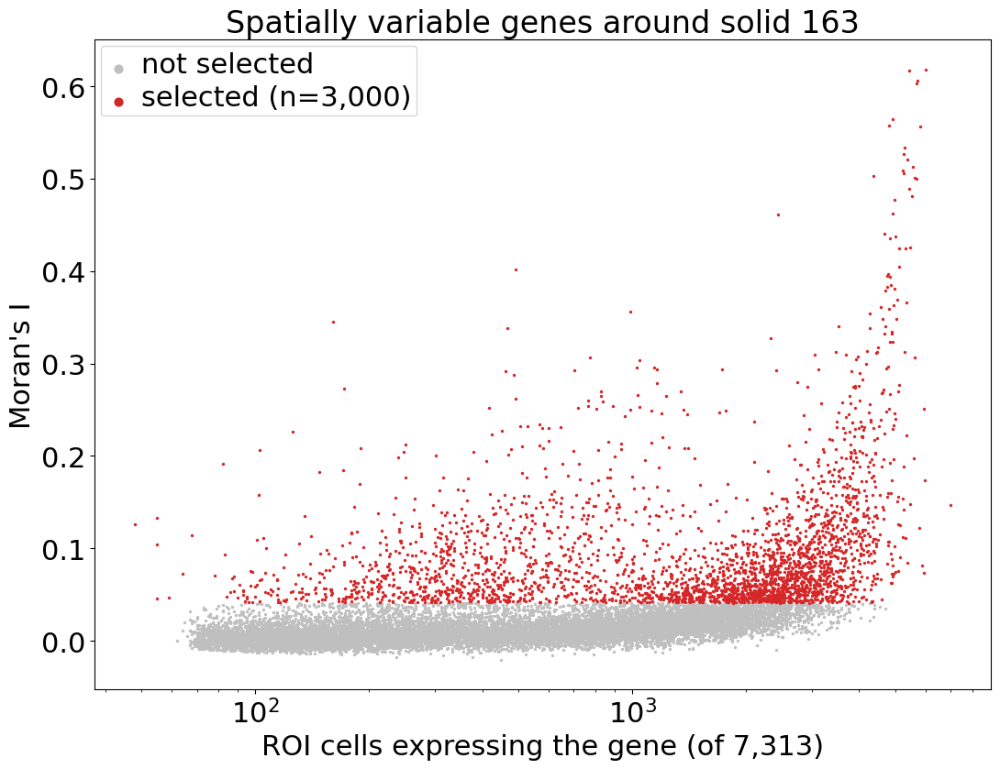

In [27]:
import squidpy as sq
N_SVG, FDR_SVG = 3000, 0.05
cand163 = list(genes163)
t0 = time.time()
ad_roi = adata[in_roi, cand163].copy()
sc.pp.normalize_total(ad_roi, target_sum=1e4); sc.pp.log1p(ad_roi)
ad_roi.obsm["spatial"] = np.c_[cell_x[in_roi], cell_y[in_roi]]
sq.gr.spatial_neighbors(ad_roi, coord_type="generic", delaunay=True)
sq.gr.spatial_autocorr(ad_roi, mode="moran", genes=cand163, n_perms=None, corr_method="fdr_bh", n_jobs=8,
                       show_progress_bar=False)
moran163 = ad_roi.uns["moranI"].copy()
moran163["n_cells_expr"] = pd.Series(np.asarray((adata[in_roi, cand163].X > 0).sum(axis=0)).ravel(), index=cand163)
sig163 = moran163[moran163["pval_norm_fdr_bh"] < FDR_SVG].sort_values("I", ascending=False)
svg163 = set(sig163.index[:N_SVG])
moran163["selected"] = moran163.index.isin(svg163)
moran163.to_csv(f"{OUT}/solid163_svg_moranI.tsv.gz", sep="\t")
genes163 = [g for g in cand163 if g in svg163]          # keep the gene order of adata
print(f"Moran's I on {ad_roi.n_obs:,} ROI cells x {len(cand163):,} genes: {time.time() - t0:.0f} s")
print(f"FDR < {FDR_SVG}: {len(sig163):,} genes;  kept (top {N_SVG:,} by I): {len(genes163):,};  "
      f"Moran's I of the last kept gene: {sig163.I.iloc[min(N_SVG, len(sig163)) - 1]:.3f}")
display(moran163.groupby("selected")[["I", "n_cells_expr"]].describe().T.round(3))

fig, ax = plt.subplots(figsize=(11, 8.5), dpi=100)
for sel, col, lab in [(False, "0.75", "not selected"), (True, "tab:red", f"selected (n={len(genes163):,})")]:
    m = moran163[moran163.selected == sel]
    ax.scatter(m.n_cells_expr, m.I, s=6, c=col, lw=0, label=lab)
ax.set_xscale("log"); ax.set_xlabel(f"ROI cells expressing the gene (of {n_roi_cells:,})")
ax.set_ylabel("Moran's I"); ax.legend(markerscale=3)
ax.set_title(f"Spatially variable genes around solid {SID}")
plt.tight_layout(); plt.show()

### 9.2 Polar histograms, MINAS similarity and PCoA

The fast all-gene versions are checked against `scomv` / `scikit-bio` on random subsets.

In [28]:
# polar histograms for all selected genes (same as scomv build_polar_distributions_for_genes)
gi163 = [vidx[g] for g in genes163]
X163 = G[mask163][:, gi163].tocsc()
A163, n_expr163, tot163 = gene_polar_counts(X163, mv163)
ok = tot163 > 0
genes163 = [g for g, o in zip(genes163, ok) if o]
A163, n_expr163, X163 = A163[ok], n_expr163[ok], X163[:, np.flatnonzero(ok)]
print(f"genes with expression in the ROI grid: {len(genes163):,}")

flat163 = flatten_min_vectors(mv163)
chk = rng.choice(len(genes163), 30, replace=False)
dmax = max(np.abs(polar_hist_for_expression(X163[:, j].toarray().ravel(), flat163, RADIUS_BINS, ANGLE_BINS, 10)
                  - A163[j]).max() for j in chk)
print(f"max |fast - scomv polar_hist_for_expression| over 30 genes: {dmax:.1e}")

genes with expression in the ROI grid: 3,000
max |fast - scomv polar_hist_for_expression| over 30 genes: 1.0e-14


In [29]:
t0 = time.time()
D163 = minas_distance(A163)
print(f"MINAS distance {D163.shape} in {time.time() - t0:.1f} s")
t0 = time.time()
pc163, eig163, prop163 = pcoa_top(D163, k=10)
print(f"PCoA (top 10 axes) in {time.time() - t0:.1f} s;  proportion explained PC1-3: {np.round(prop163[:3], 3)}")

# check against the package (MINAS) and scikit-bio (PCoA) on 300 random genes
sub = np.sort(rng.choice(len(genes163), 300, replace=False))
ref_D = minas_similarity_matrix([A163[i] for i in sub], [genes163[i] for i in sub]).values
print("MINAS max |diff| vs scomv.gene.minas_similarity_matrix:", f"{np.abs(ref_D - minas_distance(A163[sub])).max():.1e}")
ref_p = skbio_pcoa(DistanceMatrix(ref_D, ids=[genes163[i] for i in sub]))
my_c, _, my_prop = pcoa_top(ref_D, k=2)
print("PCoA PC1/PC2 max |diff| vs skbio (up to sign):",
      f"{max(np.abs(np.abs(ref_p.samples.iloc[:, j].values) - np.abs(my_c[:, j])).max() for j in range(2)):.1e}",
      " proportion explained skbio / here:", np.round(ref_p.proportion_explained.values[:2], 4), np.round(my_prop, 4))

coords163 = pd.DataFrame(pc163[:, :2], index=genes163, columns=["PC1", "PC2"])

MINAS distance (3000, 3000) in 0.2 s
PCoA (top 10 axes) in 0.1 s;  proportion explained PC1-3: [0.393 0.037 0.028]


MINAS max |diff| vs scomv.gene.minas_similarity_matrix: 3.8e-15
PCoA PC1/PC2 max |diff| vs skbio (up to sign): 9.2e-16  proportion explained skbio / here: [0.3879 0.0386] [0.3932 0.0392]


In [30]:
# inside/outside density ratio A and gene uniformity (as in the tutorial)
density_ratio163 = compute_inside_outside_density_ratio(genes163, list(A163), RADIUS_BINS, n_inside=n_inside,
                                                        n_total=n_total)
wu163 = uniformity_from_counts(A163, n_expr163, DIST_BINS, n_ref=24).set_axis(genes163)
wu_score163 = weighted_mean_across_bins(wu163, BIN_WEIGHTS)

# check WU against scomv.gene_module.compute_gene_uniformity on 50 genes
sg_chk = ad.AnnData(X=X163[:, chk[:30]].toarray(), var=pd.DataFrame(index=[genes163[i] for i in chk[:30]]))
ref_wu = gm_compute_gene_uniformity(sg_chk, list(sg_chk.var_names), [A163[i] for i in chk[:30]], DIST_BINS, n_ref=24)
print("WU max |diff| vs scomv.gene_module.compute_gene_uniformity:",
      f"{np.abs(ref_wu.values - wu163.loc[ref_wu.index].values).max():.1e}")
display(pd.DataFrame({"A (inside/outside density)": density_ratio163.describe(),
                      "WU": wu_score163.describe()}).round(3))

WU max |diff| vs scomv.gene_module.compute_gene_uniformity: 0.0e+00


,A (inside/outside density),WU
count,3000.000,3000.000
mean,0.851,0.348
std,0.573,0.158
min,0.000,0.002
25%,0.413,0.234
50%,0.917,0.357
75%,1.228,0.458
max,4.434,0.865


### 9.3 Two-stage HDBSCAN

The `min_cluster_size` grid is scaled to ~3,000 genes (tutorial: 5–20 for ~300 genes). Gene clusters are named
**G1, G2, …** (solid clusters are c1–c5): internal clusters (mean A ≥ 1.2) first, then the stage-2 clusters.

In [31]:
from scomv.gene_module import select_pcoa_cluster_params
N163 = len(genes163)
A_THRESH = 1.2
MCS_GRID = (10, 25, 50, 100, 200)                # tutorial grid (5-20 for ~300 genes), scaled to ~3,000 genes
N_CLUST_RANGE = (5, 20)                          # interpretable granularity: best DBCV among settings in this range
SWEEP1_CACHE = f"{OUT}/solid163_svg_pcoa_dbcv_stage1.tsv"  # stage-1 sweep depends only on PCoA + A (set REUSE=False to recompute)
REUSE_STAGE1_SWEEP = True
t0 = time.time()
if REUSE_STAGE1_SWEEP and os.path.exists(SWEEP1_CACHE):
    sweep1 = pd.read_csv(SWEEP1_CACHE, sep="\t")
    print("stage 1 DBCV sweep loaded from", SWEEP1_CACHE)
else:
    sweep1 = select_pcoa_cluster_params(
        coords163, extra_axes={"mean_A": (density_ratio163, [0.3, 0.5, 1.0])},
        min_cluster_sizes=MCS_GRID, cluster_selection_methods=("eom", "leaf"), cluster_selection_epsilons=(0.0, 0.1))
cand1 = sweep1[sweep1.n_clusters.between(*N_CLUST_RANGE)]
best1 = cand1.iloc[0]
print(f"stage 1 DBCV sweep: {len(sweep1)} settings ({time.time() - t0:.0f} s); overall best DBCV {sweep1.dbcv.iloc[0]:.3f} "
      f"({int(sweep1.n_clusters.iloc[0])} clusters); best with {N_CLUST_RANGE[0]}-{N_CLUST_RANGE[1]} clusters:")
display(cand1.head(5).round(3))
labels_a163, info_a163 = cluster_genes_by_pcoa(
    coords163, extra_axes={"mean_A": (density_ratio163, float(best1["mean_A_weight"]))},
    min_cluster_size=int(best1["min_cluster_size"]), cluster_selection_method=best1["cluster_selection_method"],
    cluster_selection_epsilon=float(best1["cluster_selection_epsilon"]))
print(f"stage 1: {len(info_a163)} clusters")
display(pd.DataFrame({c: {"n": i["n"], "mean_A": i["mean_A"]} for c, i in info_a163.items()}).T.round(3))

internal163 = {c: i for c, i in info_a163.items() if i["mean_A"] >= A_THRESH}
internal_genes163 = {g for i in internal163.values() for g in i["genes"]}
remaining163 = [g for g in coords163.index if g not in internal_genes163 and g in wu_score163.index]
t0 = time.time()
sweep2 = select_pcoa_cluster_params(
    coords163, extra_axes={"mean_wu": (wu_score163, [0.3, 0.5, 1.0])}, genes=remaining163,
    min_cluster_sizes=MCS_GRID, cluster_selection_methods=("eom", "leaf"), cluster_selection_epsilons=(0.0, 0.1))
cand2 = sweep2[sweep2.n_clusters.between(*N_CLUST_RANGE)]
best2 = cand2.iloc[0]
print(f"stage 2 DBCV sweep ({len(remaining163):,} genes): {len(sweep2)} settings in {time.time() - t0:.0f} s; "
      f"overall best DBCV {sweep2.dbcv.iloc[0]:.3f} ({int(sweep2.n_clusters.iloc[0])} clusters); "
      f"best with {N_CLUST_RANGE[0]}-{N_CLUST_RANGE[1]} clusters:")
display(cand2.head(5).round(3))
labels_wu163, info_wu163 = cluster_genes_by_pcoa(
    coords163, extra_axes={"mean_wu": (wu_score163, float(best2["mean_wu_weight"]))}, genes=remaining163,
    min_cluster_size=int(best2["min_cluster_size"]), cluster_selection_method=best2["cluster_selection_method"],
    cluster_selection_epsilon=float(best2["cluster_selection_epsilon"]))
sweep1.to_csv(f"{OUT}/solid163_svg_pcoa_dbcv_stage1.tsv", sep="\t", index=False)
sweep2.to_csv(f"{OUT}/solid163_svg_pcoa_dbcv_stage2.tsv", sep="\t", index=False)
unified163 = combine_cluster_summaries(("internal", internal163), ("remaining", info_wu163))
print(f"internal clusters (mean_A >= {A_THRESH}): {len(internal163)} ({len(internal_genes163):,} genes);  "
      f"stage 2: {len(info_wu163)} clusters")
summary163 = pd.DataFrame([{"cluster": f"G{k}", "source": i["source"], "n": i["n"],
                            "mean_A": np.mean([density_ratio163[g] for g in i["genes"]]),
                            "mean_WU": np.mean([wu_score163[g] for g in i["genes"]])}
                           for k, i in unified163.items()]).set_index("cluster")
display(summary163.round(3))

gene_cluster163 = pd.Series({g: f"G{k}" for k, i in unified163.items() for g in i["genes"]}, name="gene_cluster")
pd.DataFrame({"PC1": coords163.PC1, "PC2": coords163.PC2, "A": density_ratio163, "WU": wu_score163,
              "gene_cluster": gene_cluster163}).to_csv(f"{OUT}/solid163_svg_pcoa_genes_pcoa_clusters.tsv", sep="\t")

stage 1 DBCV sweep loaded from atera_results/solid163_svg_pcoa_dbcv_stage1.tsv
stage 1 DBCV sweep: 60 settings (0 s); overall best DBCV -0.370 (2 clusters); best with 5-20 clusters:


,cluster_selection_method,min_cluster_size,cluster_selection_epsilon,mean_A_weight,n_clusters,n_noise_before_soft_assign,dbcv
19,leaf,25,0.1,0.5,6,659,-0.600
25,eom,25,0.1,0.5,5,532,-0.611
26,eom,25,0.0,0.5,5,532,-0.611
27,leaf,25,0.1,0.3,7,811,-0.638
37,eom,10,0.0,1.0,15,542,-0.708


stage 1: 6 clusters


,n,mean_A
0,2098.0,1.075
1,107.0,0.725
2,183.0,0.348
3,158.0,0.676
4,149.0,0.166
5,305.0,0.080


stage 2 DBCV sweep (3,000 genes): 60 settings in 25 s; overall best DBCV -0.284 (28 clusters); best with 5-20 clusters:


,cluster_selection_method,min_cluster_size,cluster_selection_epsilon,mean_wu_weight,n_clusters,n_noise_before_soft_assign,dbcv
8,eom,10,0.0,1.0,12,285,-0.383
9,eom,10,0.1,1.0,12,285,-0.383
14,eom,25,0.0,1.0,6,343,-0.399
15,eom,25,0.1,1.0,6,343,-0.399
38,leaf,25,0.1,0.3,10,569,-0.533


internal clusters (mean_A >= 1.2): 0 (0 genes);  stage 2: 12 clusters


,source,n,mean_A,mean_WU
cluster,,,,
G1,remaining,2079,1.076,0.361
G2,remaining,80,0.738,0.059
G3,remaining,17,0.580,0.438
G4,remaining,24,0.399,0.253
G5,remaining,49,0.635,0.592
G6,remaining,29,0.421,0.505
G7,remaining,32,0.278,0.063
G8,remaining,522,0.306,0.304
G9,remaining,26,0.223,0.599


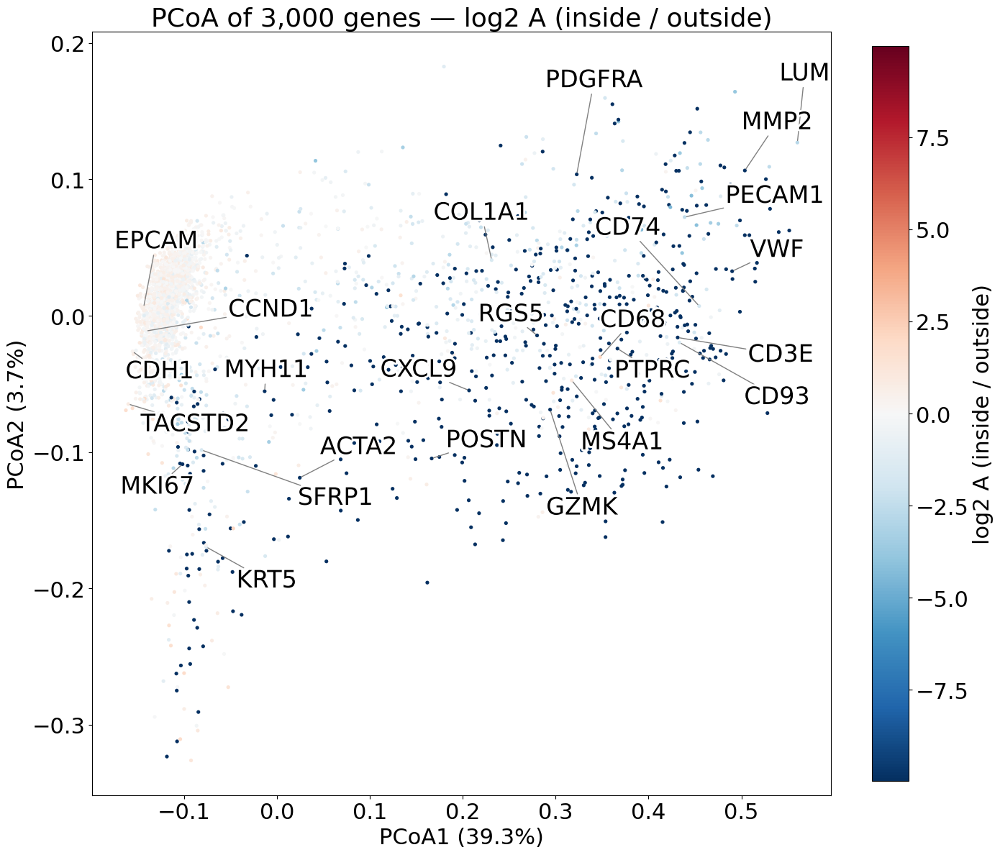

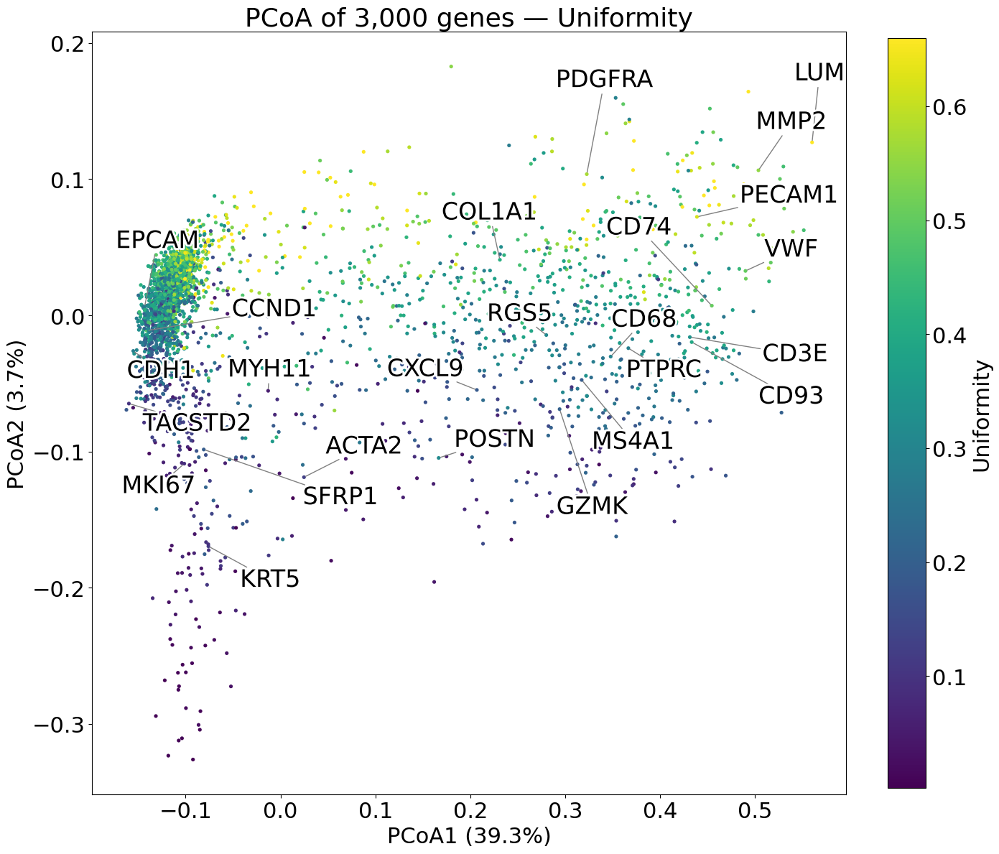

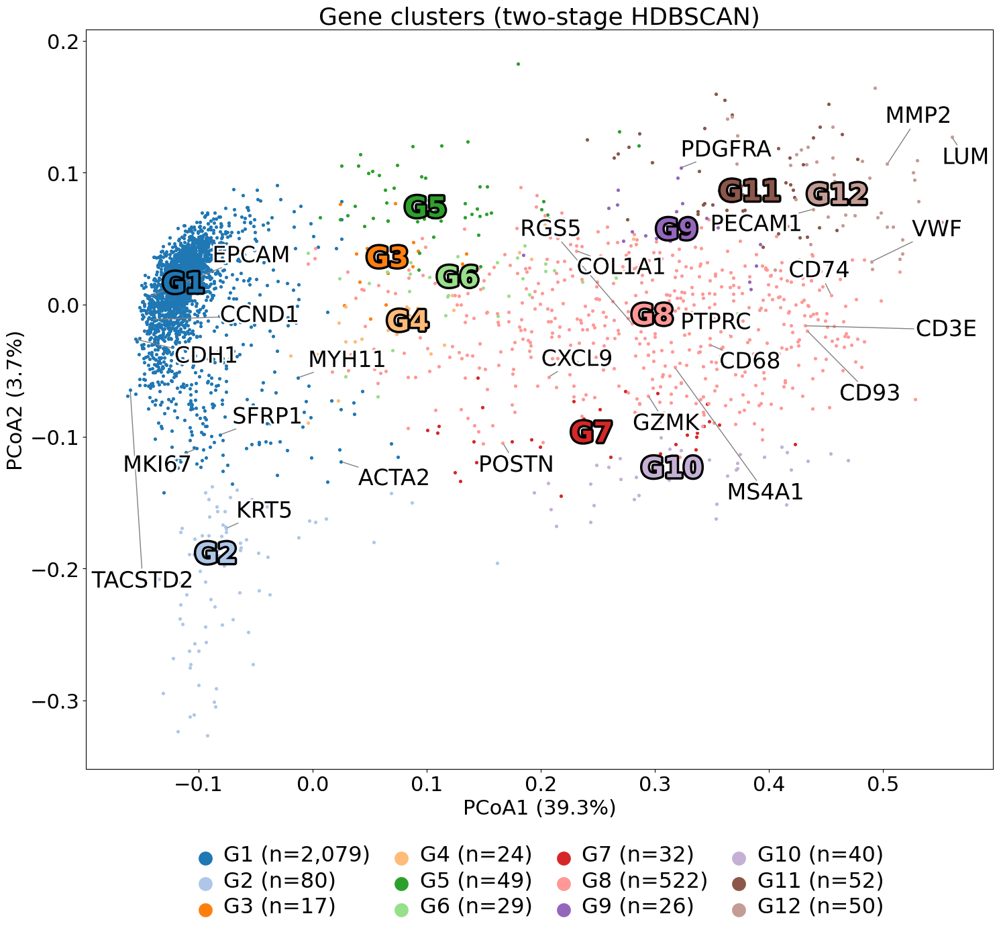

In [32]:
MARKERS163 = {"CDH1", "EPCAM", "KRT8", "KRT18", "TACSTD2", "ERBB2", "CCND1", "MKI67",          # tumor
              "CD3E", "CD8A", "GZMK", "PTPRC", "CD74", "CXCL9", "CD68", "MS4A1",              # immune
              "PECAM1", "VWF", "CD93", "RGS5",                                                # vascular
              "POSTN", "COL1A1", "LUM", "MMP2", "ACTA2", "MYH11", "KRT5", "SFRP1", "PDGFRA"}  # stroma / myoep.
cmap20 = plt.cm.tab20.colors
gcol = {k: cmap20[i % 20] for i, k in enumerate(unified163)}
import matplotlib.patheffects as pe
PC_XLAB, PC_YLAB = f"PCoA1 ({prop163[0]:.1%})", f"PCoA2 ({prop163[1]:.1%})"
OUTLINE = [pe.withStroke(linewidth=4, foreground="white")]
LABEL_PT, ID_PT = 24, 30   # gene names / cluster ids, final size (not bumped again)


def pcoa_cluster_plot(clusters, colors, prefix, title):
    # one large panel: genes coloured by cluster, marker genes labelled, cluster ids at the cluster centres
    fig, ax = plt.subplots(figsize=(15, 14), dpi=100)
    texts = []
    for k, info in clusters.items():
        c = coords163.loc[info["genes"]]
        ax.scatter(c.PC1, c.PC2, s=14, color=colors[k], lw=0, label=f"{prefix}{k} (n={info['n']:,})")
        texts += [ax.text(coords163.loc[g, "PC1"], coords163.loc[g, "PC2"], g, fontsize=LABEL_PT, path_effects=OUTLINE)
                  for g in info["genes"] if g in MARKERS163]
    ids = []
    for k, info in clusters.items():   # cluster ids fixed at the median position of each cluster
        m = coords163.loc[info["genes"]].median()
        ids.append(ax.text(m.PC1, m.PC2, f"{prefix}{k}", fontsize=ID_PT, weight="bold", color=colors[k], ha="center",
                           va="center", path_effects=[pe.withStroke(linewidth=5, foreground="black")], zorder=5))
        ids[-1]._no_font_bump = True
    for t in texts:
        t._no_font_bump = True   # final size already; must not grow after adjust_text placed it
    # obstacle points covering each cluster id (data coordinates), so gene names are pushed off the ids
    fig.canvas.draw()
    inv = ax.transData.inverted()
    obst_x, obst_y = [], []
    for t in ids:
        (x0, y0), (x1, y1) = inv.transform(t.get_window_extent())
        gx, gy = np.meshgrid(np.linspace(x0, x1, 6), np.linspace(y0, y1, 3))
        obst_x += gx.ravel().tolist(); obst_y += gy.ravel().tolist()
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=1.0),
                expand=(1.3, 1.5), force_text=(0.5, 0.8), max_move=None,
                x=obst_x, y=obst_y)   # gene names avoid the cluster ids
    ax.legend(markerscale=4, fontsize=11, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.09), frameon=False)
    ax.set_xlabel(PC_XLAB); ax.set_ylabel(PC_YLAB); ax.set_title(title, fontsize=14)
    plt.tight_layout(); plt.show()


for vals, name, cm_ in [(np.log2(density_ratio163.reindex(coords163.index).clip(lower=1e-3)), "log2 A (inside / outside)", "RdBu_r"),
                        (wu_score163.reindex(coords163.index), "Uniformity", "viridis")]:
    fig, ax = plt.subplots(figsize=(14, 12), dpi=100)
    lim = np.nanpercentile(np.abs(vals), 98) if cm_ == "RdBu_r" else None
    s_ = ax.scatter(coords163.PC1, coords163.PC2, c=vals, s=14, cmap=cm_, lw=0,
                    vmin=-lim if lim else None, vmax=lim if lim else np.nanpercentile(vals, 98))
    plt.colorbar(s_, ax=ax, fraction=0.045, label=name)
    texts = [ax.text(coords163.loc[g, "PC1"], coords163.loc[g, "PC2"], g, fontsize=LABEL_PT, path_effects=OUTLINE)
             for g in coords163.index if g in MARKERS163]
    for t in texts:
        t._no_font_bump = True
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=1.0), expand=(1.3, 1.5),
                force_text=(0.6, 0.9), max_move=None)
    ax.set_xlabel(PC_XLAB); ax.set_ylabel(PC_YLAB); ax.set_title(f"PCoA of {N163:,} genes — {name}", fontsize=14)
    plt.tight_layout(); plt.show()

pcoa_cluster_plot(unified163, gcol, "G", "Gene clusters (two-stage HDBSCAN)")

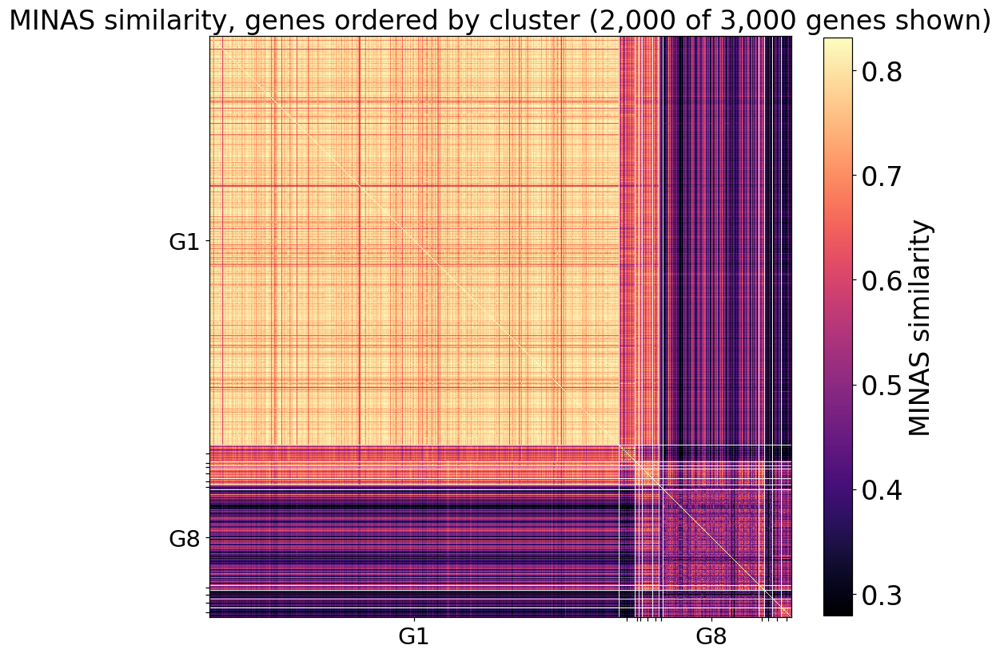

In [33]:
# similarity matrix ordered by gene cluster (random subsample of 2,000 genes for display)
order_g = [g for k in unified163 for g in unified163[k]["genes"]]
pos = {g: i for i, g in enumerate(genes163)}
pick = set(rng.choice(order_g, min(2000, len(order_g)), replace=False))
sub_g = [g for g in order_g if g in pick]
idx_sub = [pos[g] for g in sub_g]
S_sub = 1.0 - D163[np.ix_(idx_sub, idx_sub)]
fig, ax = plt.subplots(figsize=(9, 8), dpi=110)
im = ax.imshow(S_sub, cmap="magma", vmin=np.percentile(S_sub, 2), vmax=np.percentile(S_sub, 99.5), interpolation="nearest")
plt.colorbar(im, ax=ax, fraction=0.045, label="MINAS similarity")
b = np.cumsum([sum(1 for g in sub_g if gene_cluster163[g] == f"G{k}") for k in unified163])
for x in b[:-1]:
    ax.axhline(x - 0.5, color="w", lw=0.6); ax.axvline(x - 0.5, color="w", lw=0.6)
ax.set_xticks((np.r_[0, b[:-1]] + b) / 2, [f"G{k}" for k in unified163], fontsize=7)
ax.set_yticks((np.r_[0, b[:-1]] + b) / 2, [f"G{k}" for k in unified163], fontsize=7)
_w = np.diff(np.r_[0, b])   # label only blocks wide enough to hold their name
for _lab, _wi in zip(ax.get_xticklabels(), _w): _lab.set_visible(_wi >= 0.04 * b[-1])
for _lab, _wi in zip(ax.get_yticklabels(), _w): _lab.set_visible(_wi >= 0.04 * b[-1])
ax.set_title(f"MINAS similarity, genes ordered by cluster ({len(sub_g):,} of {N163:,} genes shown)", fontsize=10)
plt.tight_layout(); plt.show()

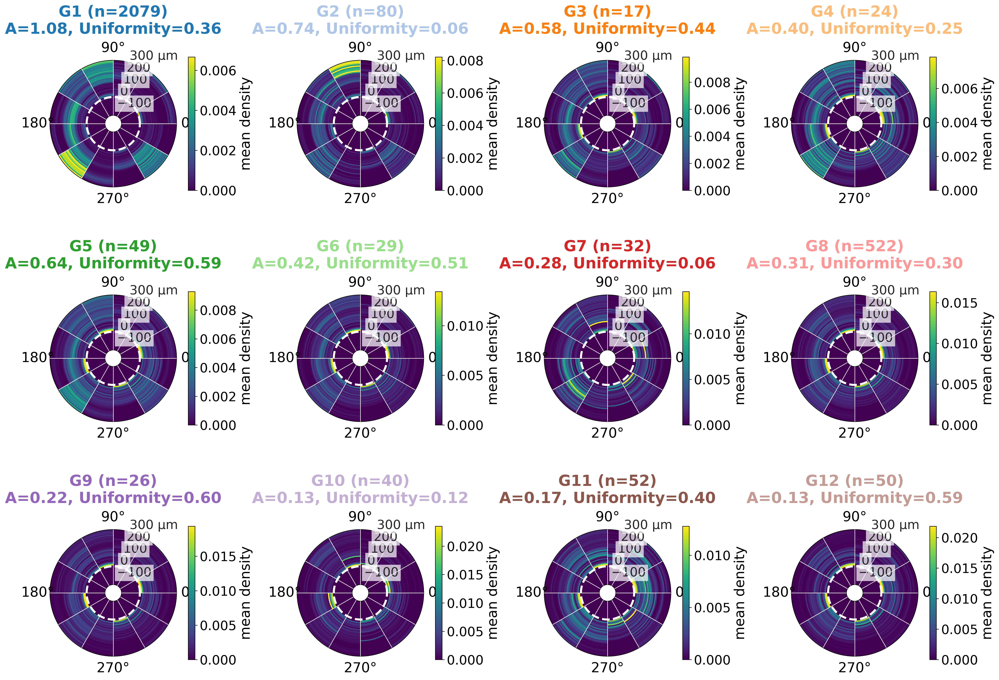

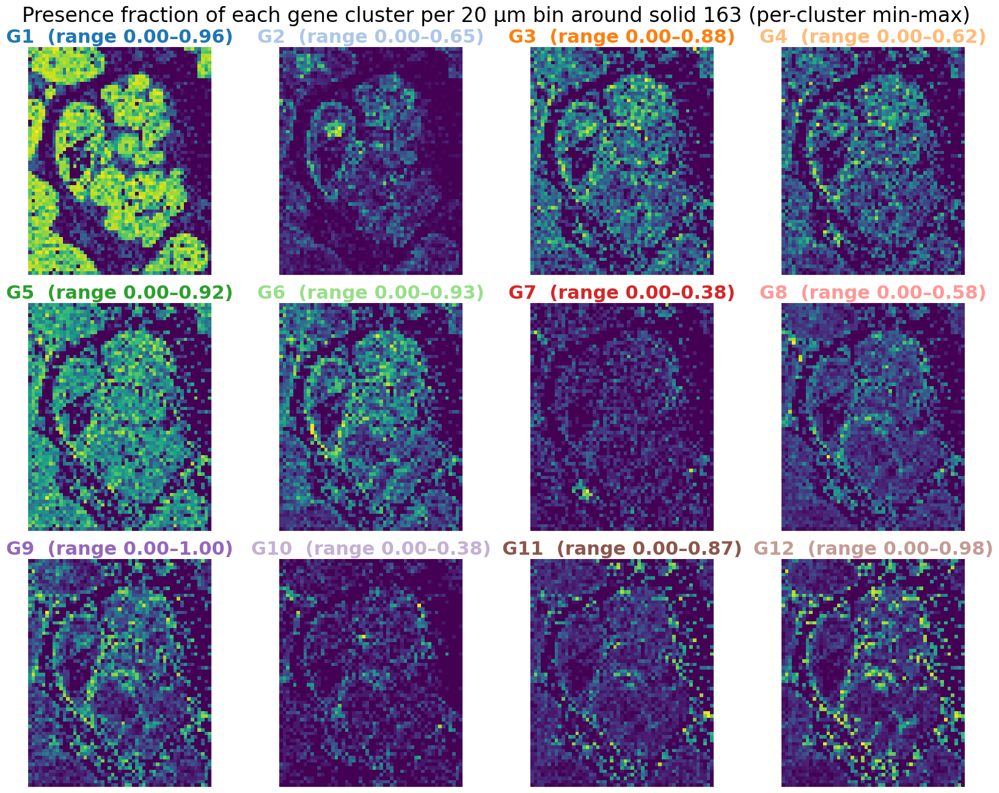

In [34]:
# mean polar distribution per gene cluster (radius -150..300 µm; dashed circle = solid boundary)
n_g = len(unified163); ncols = 4; nrows = int(np.ceil(n_g / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.8 * nrows), dpi=100, subplot_kw={"projection": "polar"})
axes = np.atleast_1d(axes).ravel()
for ax, (k, info) in zip(axes, unified163.items()):
    m = np.nanmean(A163[[pos[g] for g in info["genes"]]], axis=0)
    plot_polar_heatmap(m, RADIUS_BINS, ANGLE_BINS, ax=ax, vmin=0, vmax=np.nanpercentile(m, 99.5),
                       radius_ticks=[-100, 0, 100, 200, 300], cbar_label="mean density",
                       title=f"G{k} (n={info['n']})\nA={summary163.loc[f'G{k}', 'mean_A']:.2f}, "
                             f"Uniformity={summary163.loc[f'G{k}', 'mean_WU']:.2f}", fontsize=8)
    ax.title.set_color(gcol[k])
for ax in axes[n_g:]: ax.axis("off")
plt.tight_layout(); plt.show()

# presence fraction per 20 µm bin (min-max normalised per cluster), as in the tutorial
sg163 = ad.AnnData(X=X163, obs=grid.obs.loc[grid.obs_names[mask163], ["imagecol", "imagerow"]].copy(),
                   var=pd.DataFrame(index=genes163))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 4.4 * nrows), dpi=100)
axes = np.atleast_1d(axes).ravel()
for ax, (k, info) in zip(axes, unified163.items()):
    pm = compute_presence_fraction_map(sg163, info["genes"], bin_size_um=20)
    lo, hi = pm.min(), pm.max()
    im = ax.imshow((pm - lo) / (hi - lo) if hi > lo else pm, cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"G{k}  (range {lo:.2f}–{hi:.2f})", color=gcol[k], fontsize=10, fontweight="bold"); ax.axis("off")
for ax in axes[n_g:]: ax.axis("off")
fig.suptitle(f"Presence fraction of each gene cluster per 20 µm bin around solid {SID} (per-cluster min-max)", fontsize=12)
plt.tight_layout(); plt.show()

### 9.4 GO over-representation per gene cluster

Background = the genes entering the PCoA (the measured, expression-filtered universe). Gene-set libraries are
downloaded once by `gseapy.get_library`; the test itself runs locally (`run_go_enrichment_per_cluster`).

8 / 12 gene clusters with >= 1 significant GO term


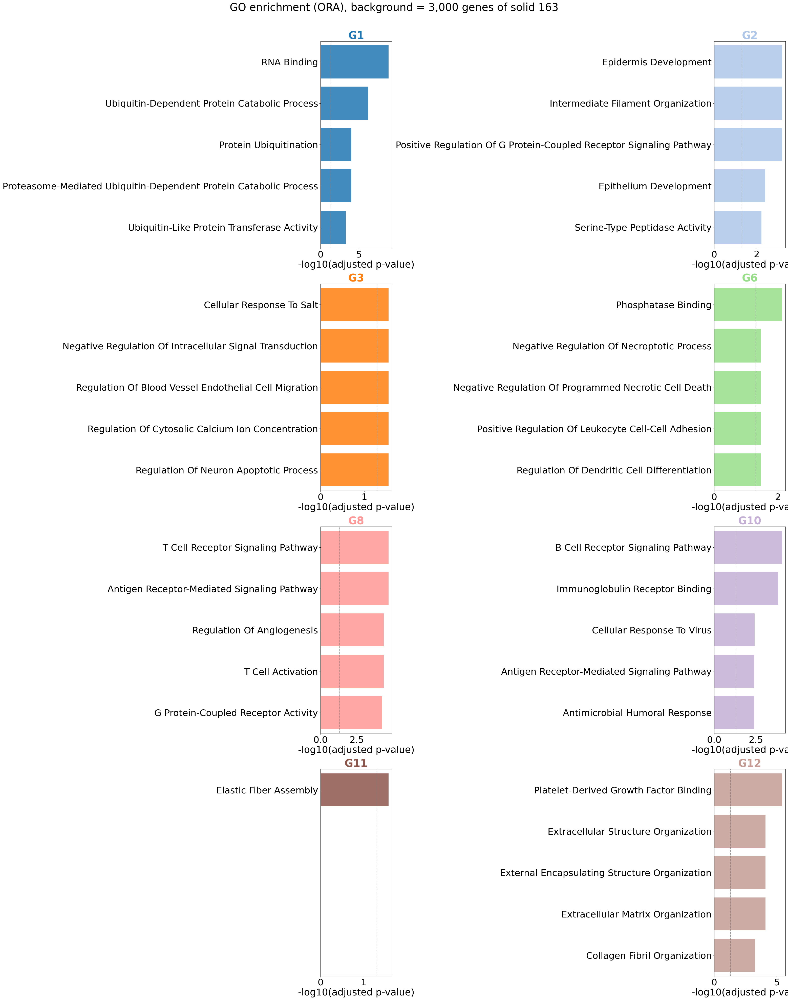

In [35]:
go_genes163 = {f"G{k}": info["genes"] for k, info in unified163.items()}
try:
    go163 = run_go_enrichment_per_cluster(go_genes163, background_genes=genes163,
                                          gene_sets=["GO_Biological_Process_2023", "GO_Molecular_Function_2023"])
    print(f"{sum(not d.empty for d in go163.values())} / {len(go163)} gene clusters with >= 1 significant GO term")
    pd.concat({k: d.head(10) for k, d in go163.items() if not d.empty}).to_csv(f"{OUT}/solid163_svg_pcoa_go_top10.tsv", sep="\t")
    fig = plot_go_enrichment_per_cluster(go163, top_n=5, n_cols=2, colors={f"G{k}": gcol[k] for k in unified163},
                                         suptitle=f"GO enrichment (ORA), background = {N163:,} genes of solid {SID}")
    if fig is not None:
        plt.show()
except Exception as e:  # network needed once for the libraries
    print("GO enrichment failed:", repr(e))

## 10. Summary

Files in `atera_results/`:

- `solid_clusters.tsv` — Ward cluster of every solid; `solid_celltype_composition.tsv` — cell groups inside each solid,
- `celltype_uniformity_one_vs_rest.tsv`, `gene_uniformity_one_vs_rest.tsv.gz` — cluster-vs-rest tests,
- `gene_uniformity_weighted_{sizefactor,raw}_solid_x_gene.csv.gz` — gene uniformity, solids × 17,878 genes,
- `solid163_svg_moranI.tsv.gz` — Moran's I of the candidate genes of the detailed solid,
- `solid163_svg_pcoa_genes_pcoa_clusters.tsv` — PCoA coordinates, A, uniformity and gene cluster per gene,
- `solid163_svg_pcoa_go_top10.tsv` — top GO terms per gene cluster.

In [36]:
print(f"Dataset: {adata.n_obs:,} cells, {adata.n_vars:,} genes (after filter); {len(feat)} tumor solids; "
      f"clusters {cluster_sizes.rename(lambda k: f'c{k + 1}').to_dict()}")
for k in TESTABLE:
    cts = sig_cells.loc[sig_cells.cluster == k, "feature"].tolist()
    ng = int(((gene_tests.cluster == k) & (gene_tests.q < 0.05)).sum())
    print(f"c{k + 1} ({cluster_sizes[k]} solids): cell types {cts};  genes q<0.05: {ng:,};  top: {top_genes[k][:10]}")

Dataset: 170,057 cells, 17,878 genes (after filter); 214 tumor solids; clusters {'c1': 7, 'c2': 22, 'c3': 16, 'c4': 116, 'c5': 53}
c1 (7 solids): cell types ['Pericytes', 'Plasma & Mast Cell Mixture', 'T Lymphocytes', 'Dendritic Cells', 'Macrophages', 'CAFs, High Grade DCIS Associated', 'Endothelial Cells', 'CXCL14+ Fibroblasts'];  genes q<0.05: 112;  top: ['GIMAP7', 'TRAC', 'CYBB', 'CD74', 'LAPTM5', 'ARHGAP4', 'GIMAP4', 'CTSS', 'EVI2B', 'HCLS1']
c2 (22 solids): cell types ['Endothelial Cells', 'Pericytes', 'Macrophages', 'CXCL14+ Fibroblasts', 'Plasma & Mast Cell Mixture', 'Dendritic Cells', 'T Lymphocytes', 'CAFs, High Grade DCIS Associated', 'CAFs, Low Grade DCIS Associated'];  genes q<0.05: 44;  top: ['PLVAP', 'SHANK3', 'PECAM1', 'LRRC32', 'APOLD1', 'GIMAP7', 'RAMP2', 'SYNPO', 'AQP1', 'ASPN']
c3 (16 solids): cell types ['Myoepithelial Cells', 'CAFs, Low Grade DCIS Associated', 'CXCL14+ Fibroblasts', 'Plasma & Mast Cell Mixture', 'Macrophages', 'Pericytes'];  genes q<0.05: 5,592;  t